<a href="https://colab.research.google.com/github/Cairo-Henrique/Intro-to-Computational-Physics-USP/blob/main/projects_data_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scientific Data Visualization — Introduction to Computational Physics

This notebook contains the Python scripts developed to visualize and analyze the numerical results obtained throughout the projects of the course **Introduction to Computational Physics (7600017)**, offered by the São Carlos Institute of Physics (IFSC-USP).

The visualizations are based on numerical data generated by the FORTRAN-77 programs developed for the course. Using Python, NumPy, and Matplotlib, the scripts transform simulation outputs into graphical representations, allowing the investigation of physical phenomena, statistical properties, numerical methods, and dynamical behavior.

## Objectives

The main purpose of this notebook is to provide graphical tools for interpreting and analyzing the results of computational experiments. The visualizations support the investigation of:

- **Statistical and stochastic systems:** probability distributions, statistical sampling, radioactive decay, random walks, and diffusion.
- **Numerical solutions of differential equations:** particle trajectories, velocity profiles, and the dynamics of nonlinear and driven oscillators.
- **Gravitational dynamics and celestial mechanics:** orbital trajectories, central-force systems, planetary perturbations, and three-body configurations.
- **Dynamical systems:** phase-space representations, energy evolution, nonlinear oscillations, and complex orbital behavior.

## Repository Structure

The notebook is organized into sections corresponding to the projects for which graphical analysis was developed:

| Section | Project | Main Topics |
|:---:|---|---|
| 1 | Project 2 — Random Systems | Statistical distributions, radioactive decay, and random walks |
| 2 | Project 4 — Differential Equations | Numerical integration, projectile motion, pendulum dynamics, and nonlinear oscillations |
| 3 | Project 5 — Kepler's Laws and the Three-Body Problem | Orbital mechanics, central forces, planetary dynamics, and three-body choreographies |

Each section contains the scripts associated with the corresponding computational tasks, including comparisons between numerical results, theoretical predictions, and different simulation parameters whenever applicable.

## Technologies and Libraries

The notebook is implemented in Python and relies primarily on the following libraries:

- **NumPy:** numerical data processing, array manipulation, and mathematical operations.
- **Matplotlib:** two-dimensional plotting, statistical visualizations, phase-space diagrams, and orbital trajectories.
- **Matplotlib Animation:** generation of animations for time-dependent dynamical systems.

## Data Input and Execution

The scripts read numerical output files (`.dat`) generated by the corresponding FORTRAN-77 programs. Most visualizations use `numpy.loadtxt()` to import these files and extract the relevant physical quantities.

To reproduce the visualizations:

1. Compile and execute the corresponding FORTRAN-77 programs using GNU Fortran (`gfortran`).
2. Generate the numerical output files required by each plotting script.
3. Make the output files available in the notebook's working directory.
4. Execute the corresponding Python cells to generate the visualizations.

**Note:** Some scripts use paths specific to Google Colab (e.g., `/content/`), while others use relative file paths. When running the notebook in a different environment, these paths may need to be adjusted accordingly.

## Computational Workflow

The general workflow adopted throughout the projects can be summarized as follows:

1. **Numerical Simulation:** physical systems are modeled and simulated using FORTRAN-77.
2. **Data Generation:** the numerical results are exported to text files in `.dat` format.
3. **Data Processing:** Python and NumPy are used to load, organize, and manipulate the simulation data.
4. **Visualization:** Matplotlib is employed to construct plots, compare numerical results, and investigate the behavior of the simulated systems.

This separation between numerical computation and graphical analysis allows the FORTRAN-77 programs to focus on implementing the numerical algorithms, while Python provides a flexible environment for data visualization and interpretation.

---

**Course:** Introduction to Computational Physics (7600017)  
**Institution:** São Carlos Institute of Physics — University of São Paulo (IFSC-USP)  
**Programming Language:** FORTRAN-77  
**Visualization:** Python, NumPy, and Matplotlib

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

## Projeto 2

### Tarefa 1

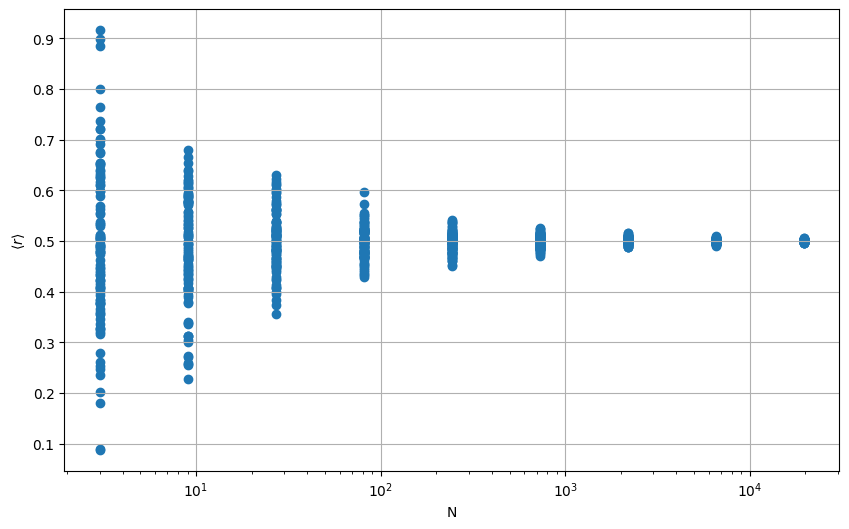

In [ ]:
arquivo = '/content/tarefa-1a-saida-1.dat'

dados = np.loadtxt(arquivo)

x = dados[:, 0]
y = dados[:, 1]

plt.figure(figsize=(10, 6))

plt.scatter(x, y)

plt.xlabel("N")
plt.ylabel(r"$\langle r \rangle$")

plt.xscale('log')

plt.gca().yaxis.set_major_locator(MultipleLocator(0.1))
plt.grid()

plt.show()

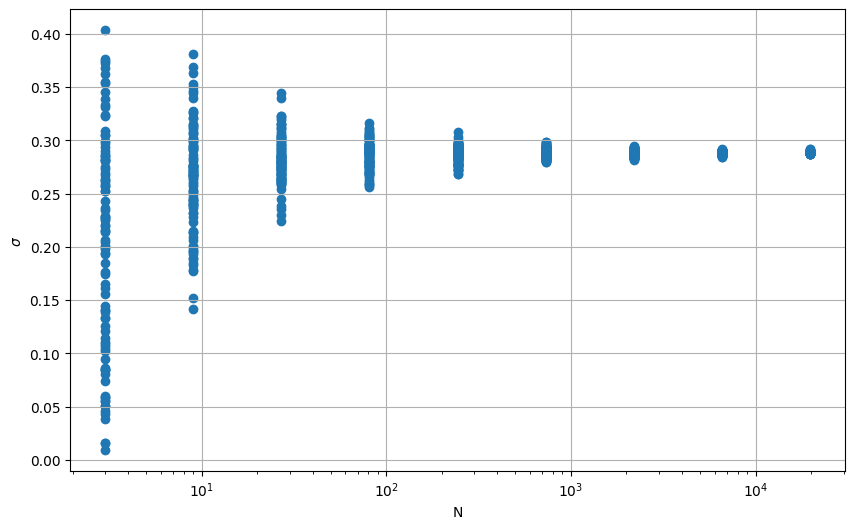

In [ ]:
arquivo = '/content/tarefa-1a-saida-2.dat'

dados = np.loadtxt(arquivo)

x = dados[:, 0]
y = dados[:, 1]

plt.figure(figsize=(10, 6))

plt.scatter(x, y)

plt.xlabel("N")
plt.ylabel(r"$\sigma$")

plt.xscale('log')

plt.gca().yaxis.set_major_locator(MultipleLocator(0.05))
plt.grid()

plt.show()

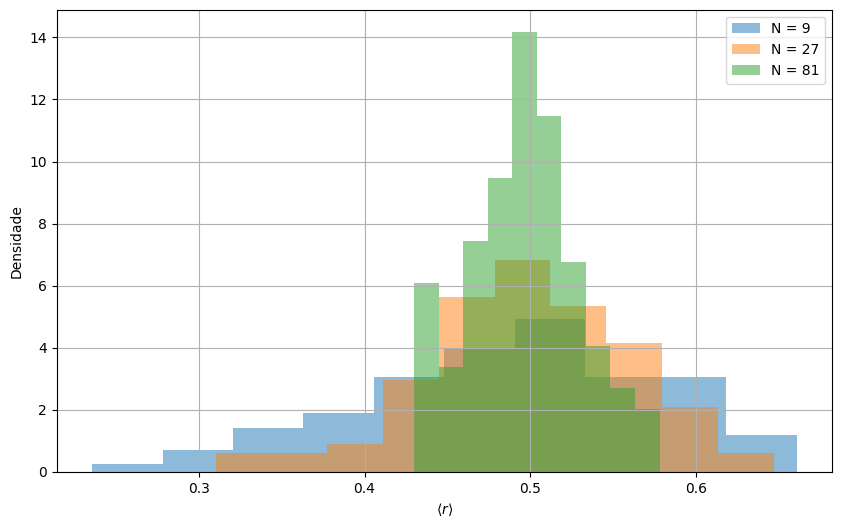

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivo = '/content/tarefa-1b-saida-1.dat'

dados = np.loadtxt(arquivo)

N = dados[:, 0]
valores = dados[:, 1]

plt.figure(figsize=(10, 6))

for n in np.unique(N):
    valores_n = valores[N == n]
    plt.hist(
    valores_n,
    bins=10,
    alpha=0.5,
    label='N = {}'.format(int(n)),
    density=True
)

plt.xlabel(r"$\langle r \rangle$")
plt.ylabel("Densidade")

plt.legend()
plt.grid()

plt.show()

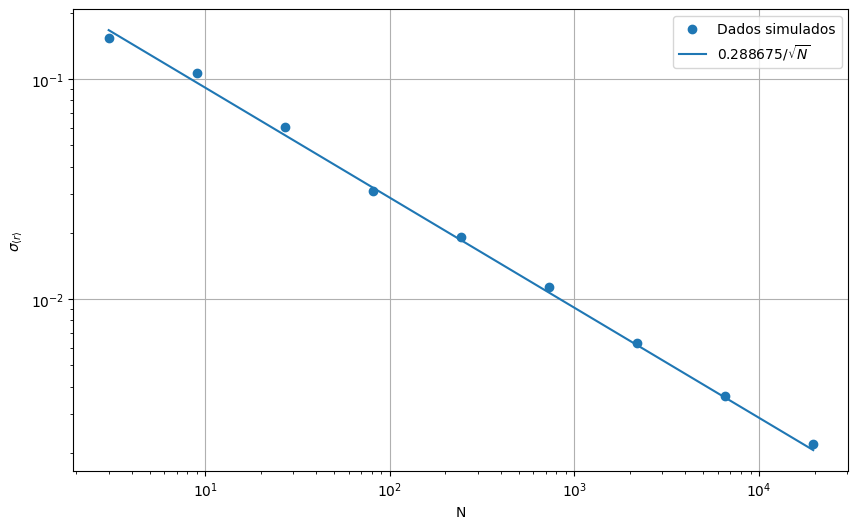

In [ ]:
arquivo = '/content/tarefa-1b-saida-2.dat'

dados = np.loadtxt(arquivo)

x = dados[:, 0]
y = dados[:, 1]

# Curva teórica
y_teorico = 0.288675 / np.sqrt(x)

plt.figure(figsize=(10, 6))

plt.scatter(x, y, label='Dados simulados')

plt.plot(x, y_teorico, label=r'$0.288675/\sqrt{N}$')

plt.xlabel("N")

plt.ylabel(r"$\sigma_{\langle r \rangle}$")

plt.xscale('log')

plt.yscale('log')

plt.grid()

plt.legend()

plt.show()

### Tarefa 2

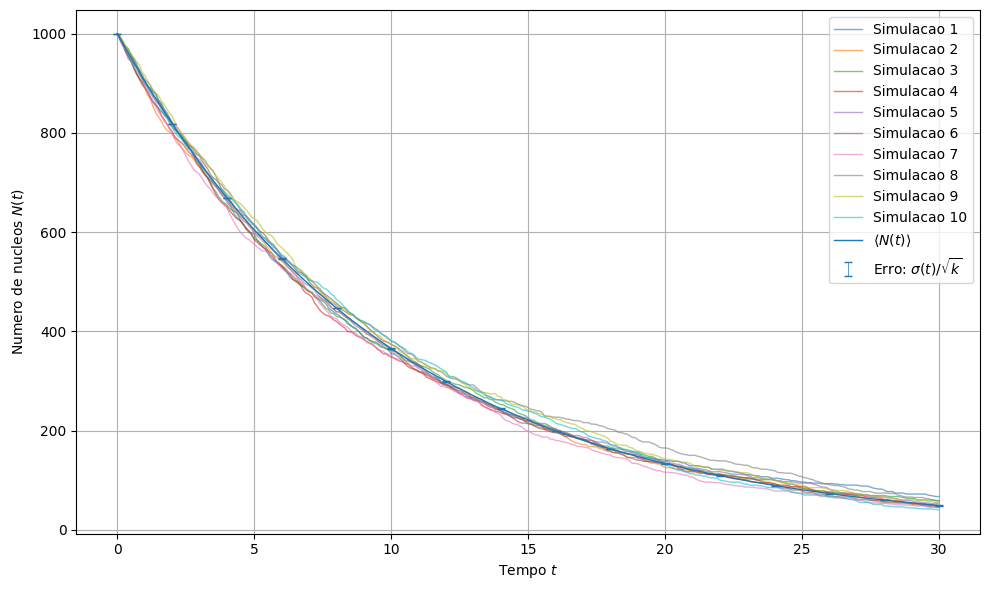

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivo = 'tarefa-2b-saida-1.dat'

dados = np.loadtxt(arquivo)

t = dados[:, 0]

# Dez primeiras simulacoes
N = dados[:, 1:11]

# Media e barra de erro
N_medio = dados[:, 11]
erro = dados[:, 12]

plt.figure(figsize=(10, 6))

# Plota as dez primeiras simulacoes
for i in range(10):
    plt.plot(t, N[:, i], linewidth=1, alpha=0.6,
             label='Simulacao {}'.format(i + 1))

# Plota a media com barras de erro
plt.errorbar(
    t[::20],
    N_medio[::20],
    yerr=erro[::20],
    fmt='none',
    capsize=3,
    elinewidth=0.5,
    label=r'Erro: $\sigma(t)/\sqrt{k}$'
)

plt.plot(
    t,
    N_medio,
    linewidth=1,
    label=r'$\langle N(t) \rangle$'
)

plt.xlabel(r'Tempo $t$')
plt.ylabel(r'Numero de nucleos $N(t)$')
plt.grid()
plt.legend()
plt.tight_layout()

plt.show()

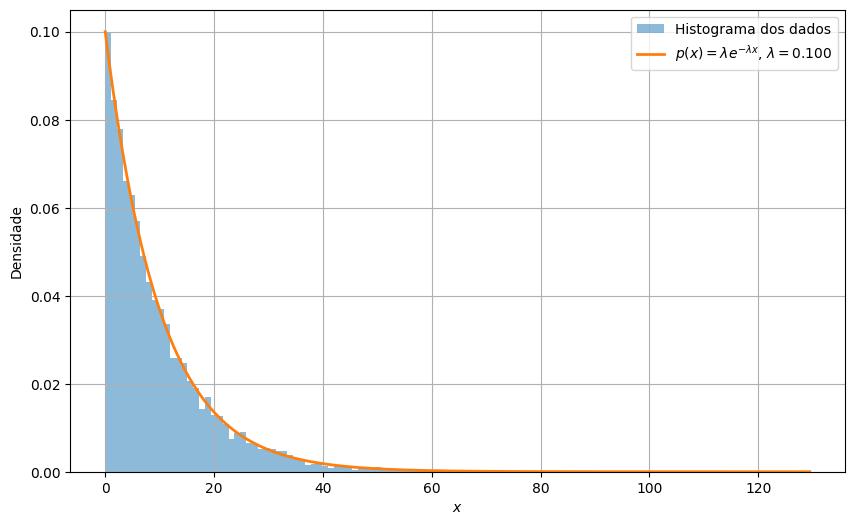

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivo = '/content/tarefa-2c-saida-1.dat'

dados = np.loadtxt(arquivo)

valores = dados[:]

# Estimativa de lambda pela média dos dados
lambda_ = 0.1

# Pontos para a curva teórica
x = np.linspace(0, np.max(valores), 1000)

# Distribuição exponencial
p = lambda_ * np.exp(-lambda_ * x)

plt.figure(figsize=(10, 6))

# Histograma normalizado
plt.hist(
    valores,
    bins=120,
    alpha=0.5,
    density=True,
    label="Histograma dos dados"
)

# Distribuição exponencial teórica
plt.plot(
    x,
    p,
    linewidth=2,
    label=rf"$p(x)=\lambda e^{{-\lambda x}}$, $\lambda={lambda_:.3f}$"
)

plt.xlabel(r"$x$")
plt.ylabel(r"Densidade")

plt.legend()

plt.grid()

plt.show()

### Tarefa 3

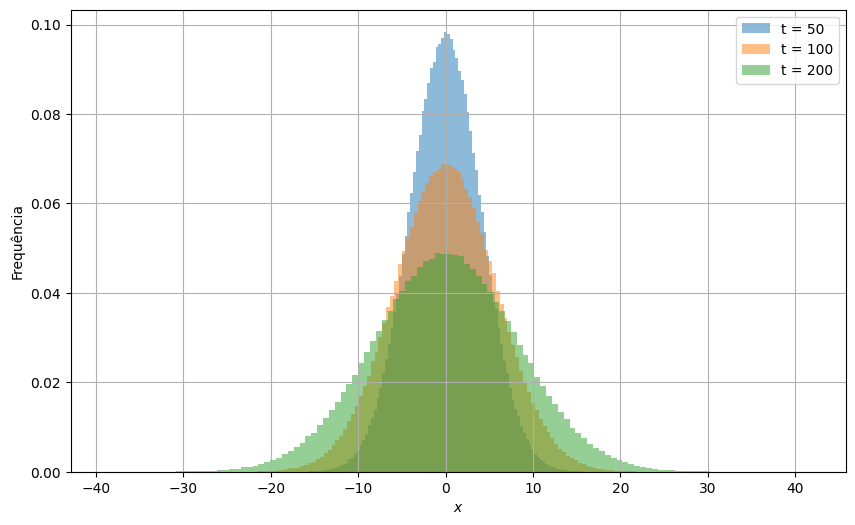

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivo = '/content/tarefa-3a-saida-1.dat'

dados = np.loadtxt(arquivo)

t = dados[:, 0]
valores = dados[:, 1]

plt.figure(figsize=(10, 6))

for i in np.unique(t):
    valores_t = valores[t == i]
    plt.hist(valores_t, bins=120, alpha=0.5, label='t = {}'.format(int(i)), density=True)

plt.xlabel(r"$x$")
plt.ylabel("Densidade")

plt.legend()
plt.grid()

plt.show()

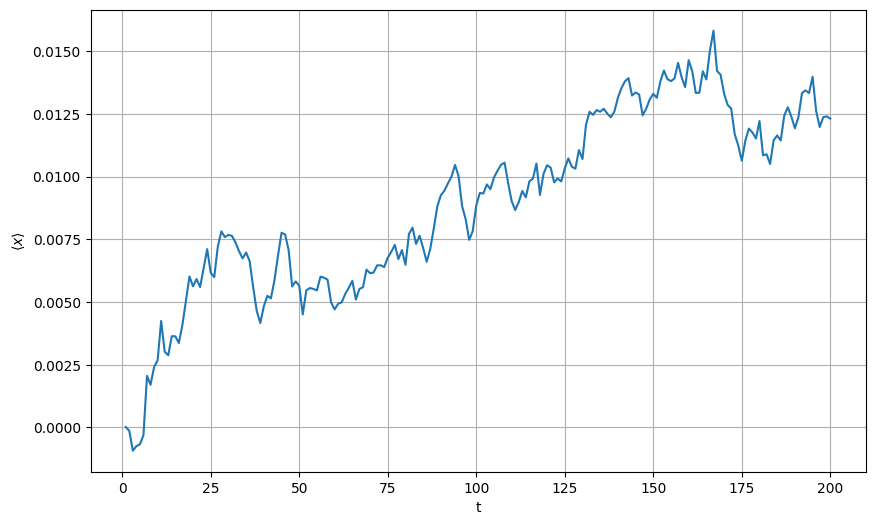

In [ ]:
arquivo = '/content/tarefa-3a-saida-2.dat'

dados = np.loadtxt(arquivo)

x = dados[:, 0]
y = dados[:, 1]

plt.figure(figsize=(10, 6))

plt.plot(x, y)

plt.xlabel("t")
plt.ylabel(r"$\langle x \rangle$")

#plt.xscale('log')
#plt.yscale('log')

#plt.gca().yaxis.set_major_locator(MultipleLocator(0.05))
plt.grid()

plt.show()

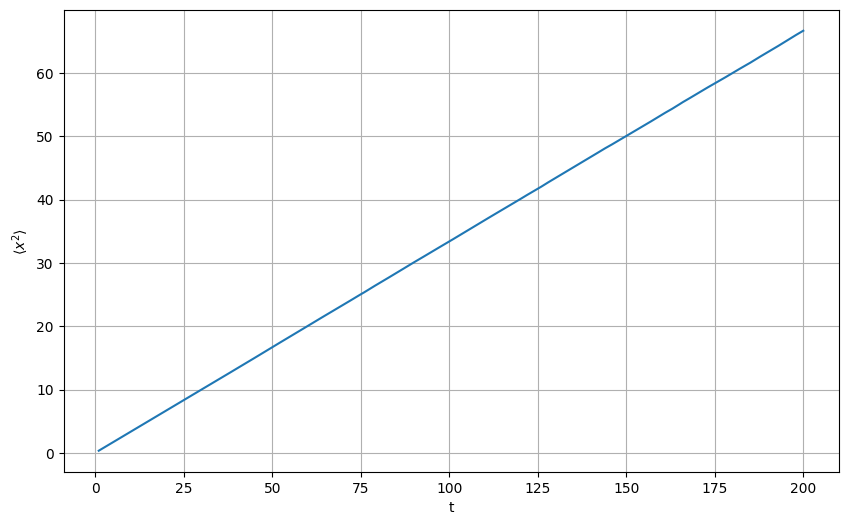

In [ ]:
arquivo = '/content/tarefa-3a-saida-3.dat'

dados = np.loadtxt(arquivo)

x = dados[:, 0]
y = dados[:, 1]

plt.figure(figsize=(10, 6))

plt.plot(x, y)

plt.xlabel("t")
plt.ylabel(r"$\langle x^2 \rangle$")

#plt.xscale('log')
#plt.yscale('log')

#plt.gca().yaxis.set_major_locator(MultipleLocator(0.05))
plt.grid()

plt.show()

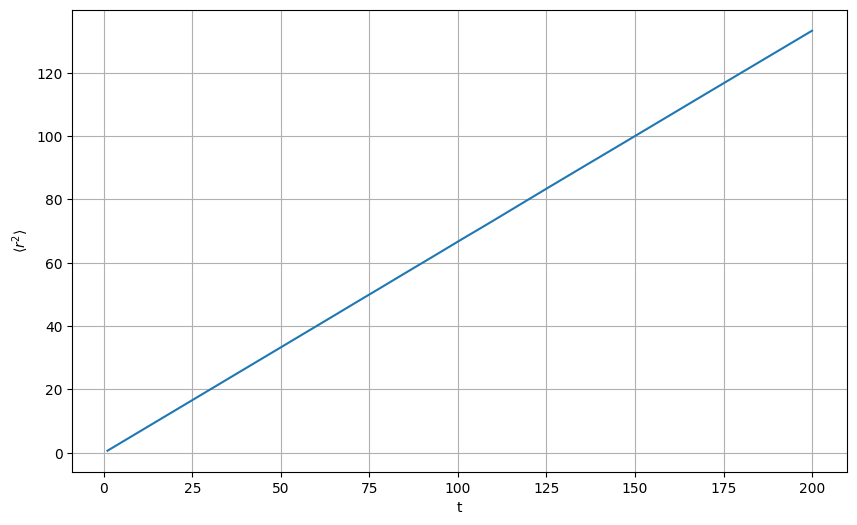

In [ ]:
arquivo = '/content/tarefa-3b-saida-1.dat'

dados = np.loadtxt(arquivo)

x = dados[:, 0]
y = dados[:, 1]

plt.figure(figsize=(10, 6))

plt.plot(x, y)

plt.xlabel("t")
plt.ylabel(r"$\langle r^2 \rangle$")

#plt.xscale('log')
#plt.yscale('log')

#plt.gca().yaxis.set_major_locator(MultipleLocator(0.05))
plt.grid()

plt.show()

## Projeto 4

### Tarefa 1

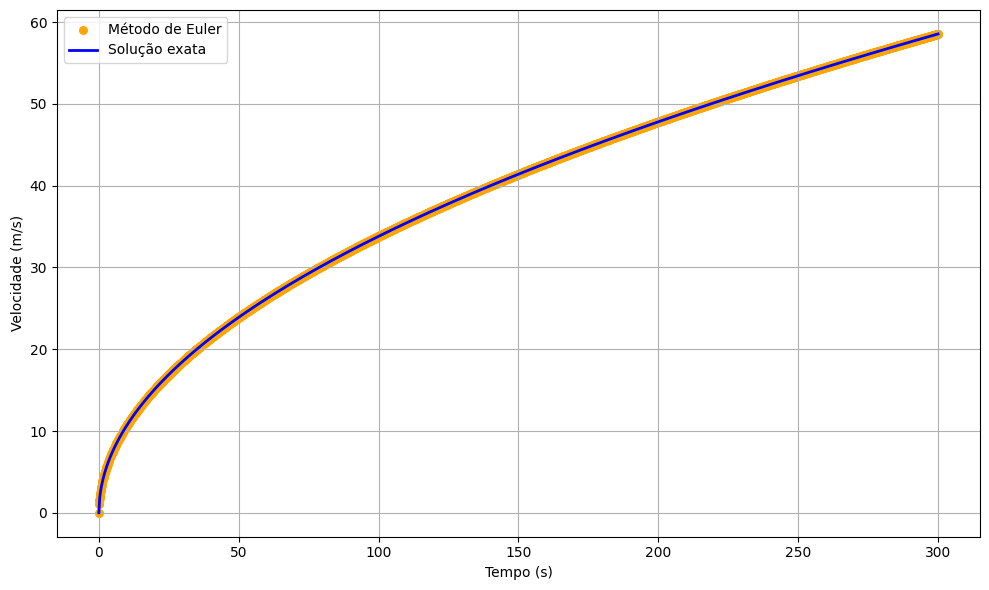

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivo = '/content/tarefa-1a-saida-1.dat'
dados = np.loadtxt(arquivo)

t = dados[:, 0]
v = dados[:, 1]

# Parâmetros do problema
m = 70.0       # massa (kg)
P_c = 400.0    # potência (W)
v0 = 0.0       # velocidade inicial (m/s): use o mesmo valor do Fortran

# Solução exata: v(t) = sqrt(v0² + 2*P_c*t/m)
t_exato = np.linspace(t[0], t[-1], 1000)
v_exato = np.sqrt(v0**2 + 2.0 * P_c * t_exato / m)

# Gráfico comparativo
plt.figure(figsize=(10, 6))

plt.scatter(t, v, label='Método de Euler', color='orange', s=30)
plt.plot(t_exato, v_exato, label='Solução exata', color='blue', linewidth=2)

plt.xlabel('Tempo (s)')
plt.ylabel('Velocidade (m/s)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

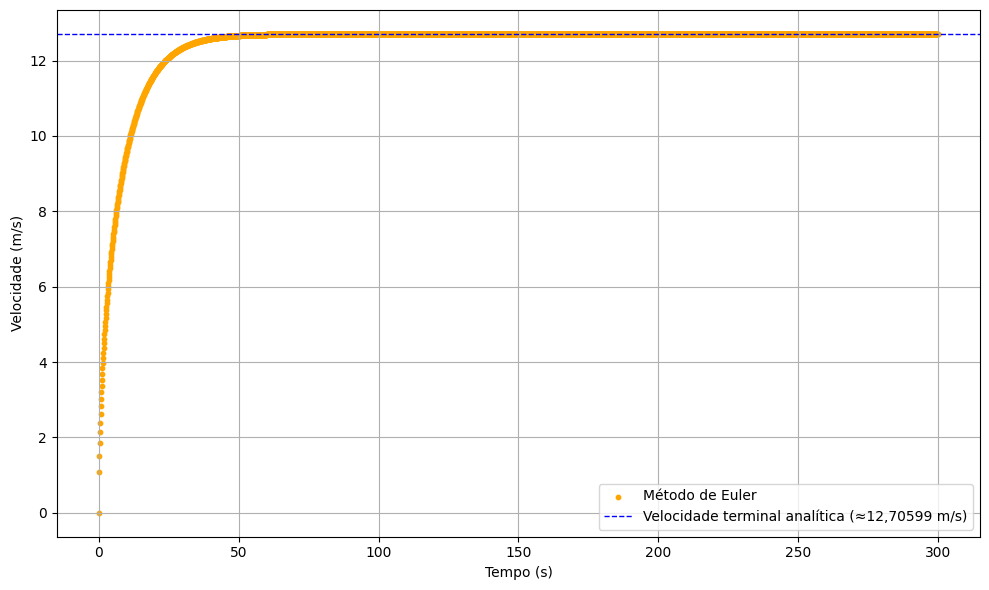

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivo = '/content/tarefa-1b-saida-1.dat'
dados = np.loadtxt(arquivo)

t = dados[:, 0]
v = dados[:, 1]

# Velocidade terminal analítica
P_c = 400.0
rho = 1.3
A = 0.3

v_terminal = (2 * P_c / (rho * A))**(1/3)

# Gráfico comparativo
plt.figure(figsize=(10, 6))

plt.scatter(t, v, label='Método de Euler', color='orange', s=10)
plt.axhline(v_terminal, label='Velocidade terminal analítica (≈12,70599 m/s)',
            color='blue', linewidth=1, linestyle='--')

plt.xlabel('Tempo (s)')
plt.ylabel('Velocidade (m/s)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

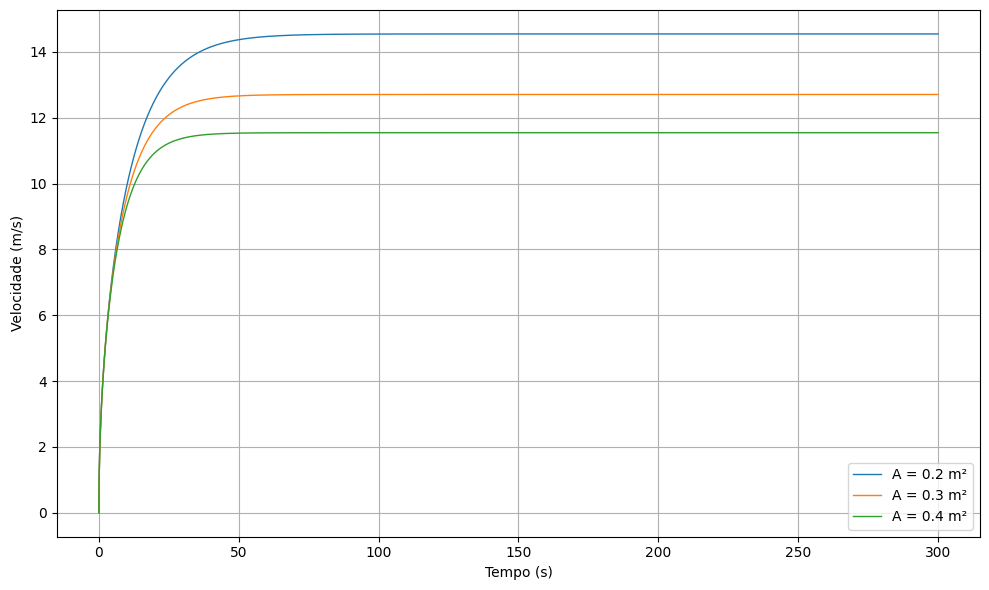

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Arquivos de saída
arquivos = [
    '/content/tarefa-1c-saida-1.dat',
    '/content/tarefa-1c-saida-2.dat',
    '/content/tarefa-1c-saida-3.dat'
]

# Áreas frontais correspondentes (m²)
areas = [0.2, 0.3, 0.4]

plt.figure(figsize=(10, 6))

for arquivo, A in zip(arquivos, areas):
    dados = np.loadtxt(arquivo)

    t = dados[:, 0]
    v = dados[:, 1]

    plt.plot(t, v, label=f'A = {A} m²', linewidth=1)

plt.xlabel('Tempo (s)')
plt.ylabel('Velocidade (m/s)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Tarefa 2

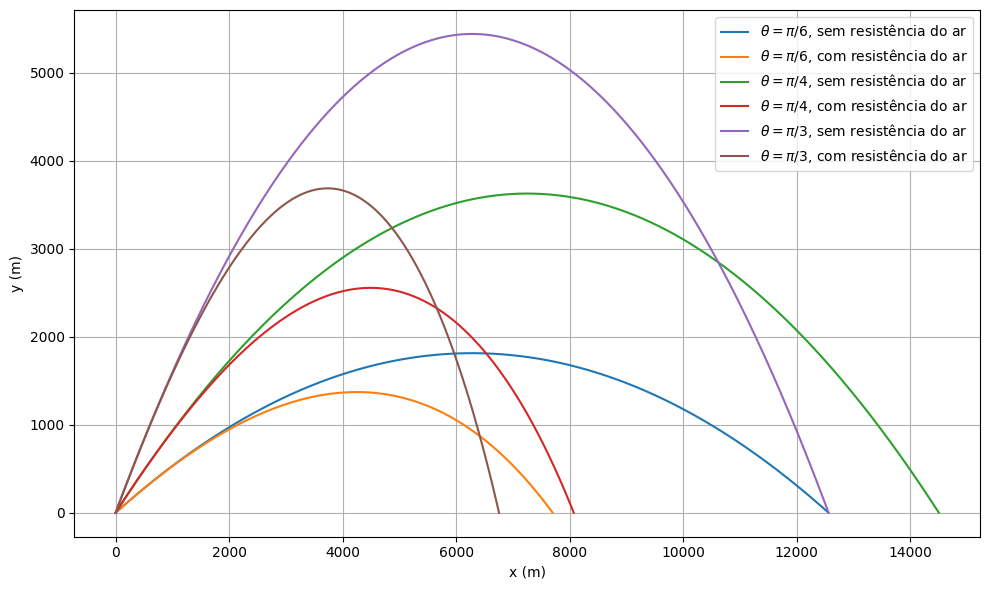

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivos = [
    ("tarefa-2a-saida-1.dat", r"$\theta=\pi/6$, sem resistência do ar"),
    ("tarefa-2a-saida-2.dat", r"$\theta=\pi/6$, com resistência do ar"),
    ("tarefa-2a-saida-3.dat", r"$\theta=\pi/4$, sem resistência do ar"),
    ("tarefa-2a-saida-4.dat", r"$\theta=\pi/4$, com resistência do ar"),
    ("tarefa-2a-saida-5.dat", r"$\theta=\pi/3$, sem resistência do ar"),
    ("tarefa-2a-saida-6.dat", r"$\theta=\pi/3$, com resistência do ar")
]

plt.figure(figsize=(10, 6))

for arquivo, legenda in arquivos:
    dados = np.loadtxt(arquivo)
    x = dados[:, 0]
    y = dados[:, 1]
    plt.plot(x, y, label=legenda)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

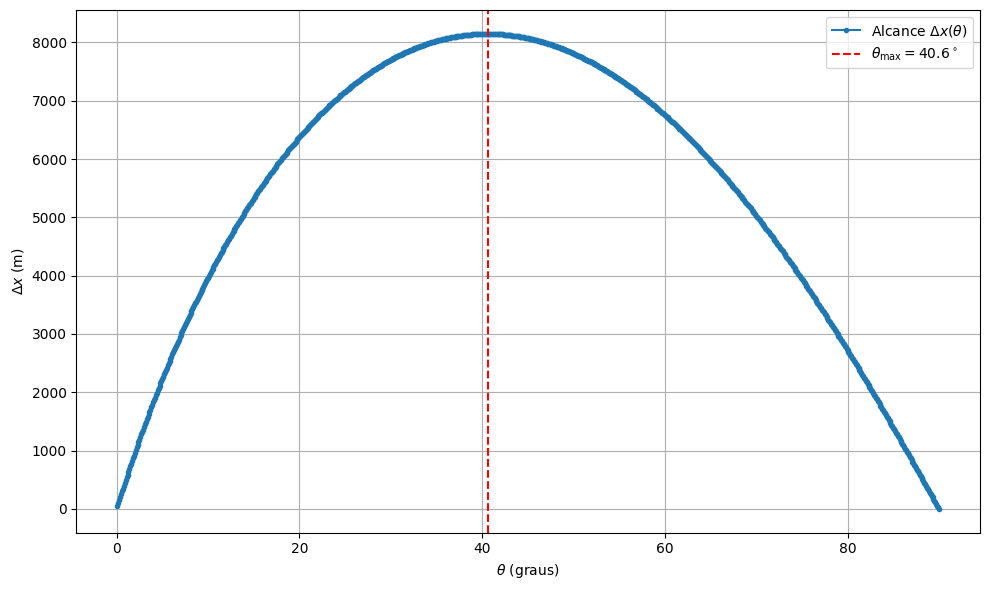

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Lê os dados gerados pelo programa Fortran
dados = np.loadtxt("tarefa-2b-saida-1.dat")

theta = np.degrees(dados[:, 0])  # Converte de radianos para graus
Delta_x = dados[:, 1]

# Gráfico do alcance em função do ângulo
plt.figure(figsize=(10, 6))
plt.plot(theta, Delta_x, "o-", markersize=3,
         label=r"Alcance $\Delta x(\theta)$")

# Reta vertical no ângulo máximo
theta_max = 40.6
plt.axvline(x=theta_max, linestyle="--", color="red",
            label=r"$\theta_{\max}=40.6^\circ$")

plt.xlabel(r"$\theta$ (graus)")
plt.ylabel(r"$\Delta x$ (m)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

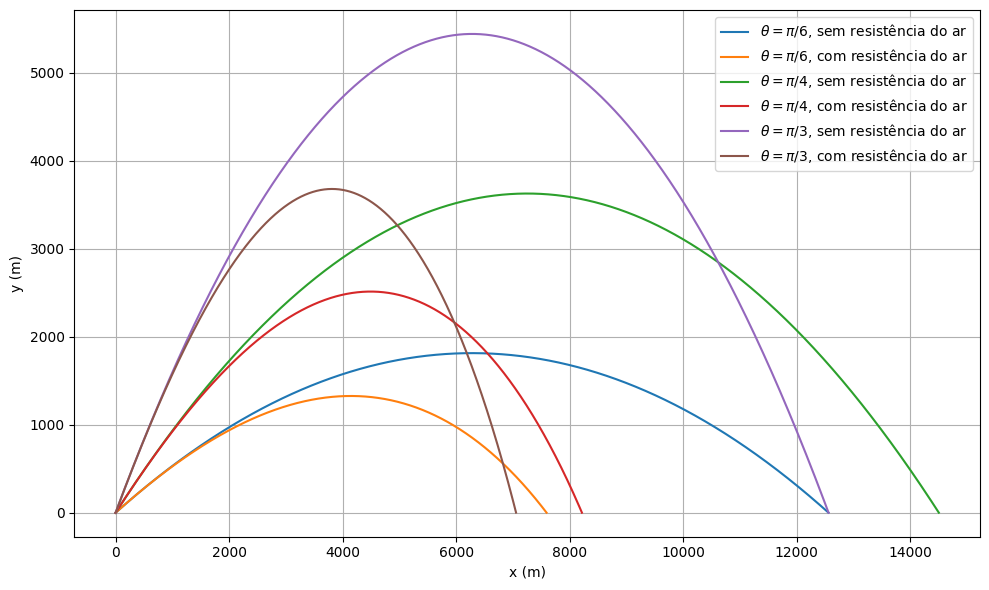

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arquivos = [
    ("tarefa-2c-saida-1.dat", r"$\theta=\pi/6$, sem resistência do ar"),
    ("tarefa-2c-saida-2.dat", r"$\theta=\pi/6$, com resistência do ar"),
    ("tarefa-2c-saida-3.dat", r"$\theta=\pi/4$, sem resistência do ar"),
    ("tarefa-2c-saida-4.dat", r"$\theta=\pi/4$, com resistência do ar"),
    ("tarefa-2c-saida-5.dat", r"$\theta=\pi/3$, sem resistência do ar"),
    ("tarefa-2c-saida-6.dat", r"$\theta=\pi/3$, com resistência do ar")
]

plt.figure(figsize=(10, 6))

for arquivo, legenda in arquivos:
    dados = np.loadtxt(arquivo)
    x = dados[:, 0]
    y = dados[:, 1]
    plt.plot(x, y, label=legenda)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

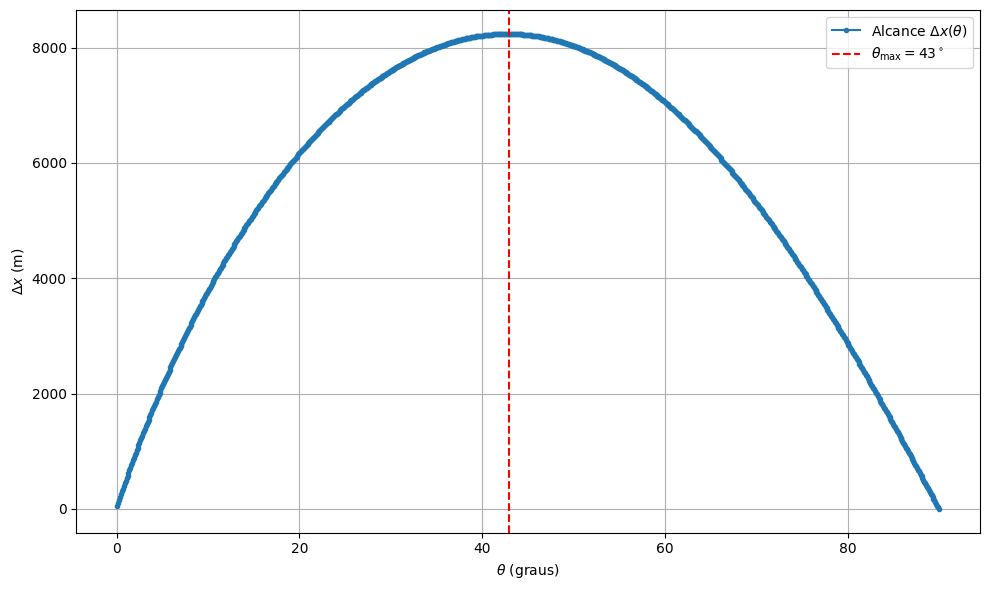

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Lê os dados gerados pelo programa Fortran
dados = np.loadtxt("tarefa-2c-saida-7.dat")

theta = np.degrees(dados[:, 0])  # Converte de radianos para graus
Delta_x = dados[:, 1]

# Gráfico do alcance em função do ângulo
plt.figure(figsize=(10, 6))
plt.plot(theta, Delta_x, "o-", markersize=3,
         label=r"Alcance $\Delta x(\theta)$")

# Reta vertical no ângulo máximo
theta_max = 43
plt.axvline(x=theta_max, linestyle="--", color="red",
            label=r"$\theta_{\max}=43^\circ$")

plt.xlabel(r"$\theta$ (graus)")
plt.ylabel(r"$\Delta x$ (m)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

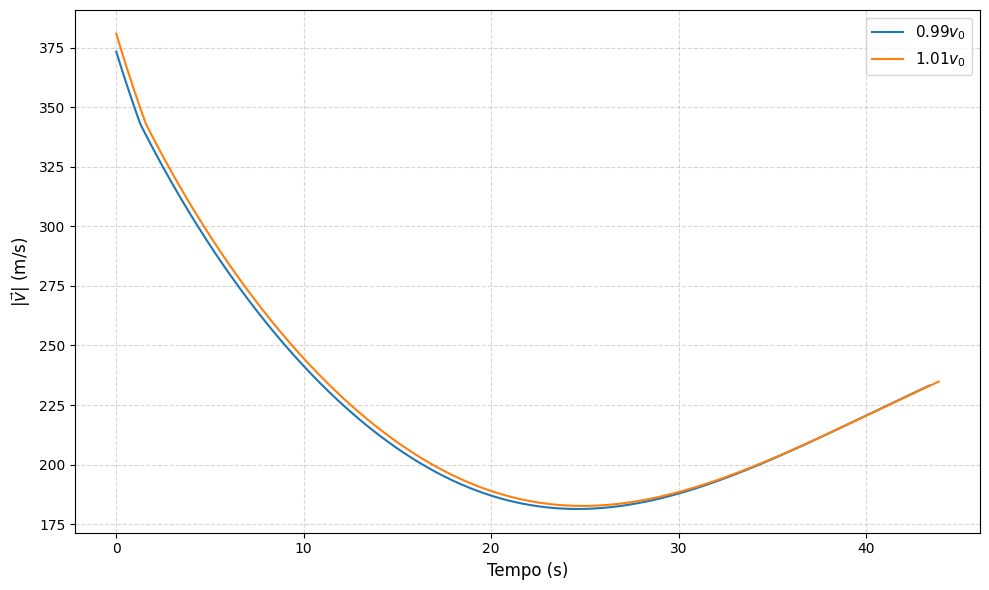

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Arquivos de entrada
arquivo_8 = 'tarefa-2c-saida-8.dat'
arquivo_9 = 'tarefa-2c-saida-9.dat'

# Leitura dos dados
dados_8 = np.loadtxt(arquivo_8)
dados_9 = np.loadtxt(arquivo_9)

# Separação das colunas
t_8, v_8 = dados_8[:, 0], dados_8[:, 1]
t_9, v_9 = dados_9[:, 0], dados_9[:, 1]

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(t_8, v_8, label=r'$0.99v_0$')
plt.plot(t_9, v_9, label=r'$1.01v_0$')

plt.xlabel('Tempo (s)', fontsize=12)
plt.ylabel(r'$|\vec{v}|$ (m/s)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()

plt.show()

### Tarefa 3

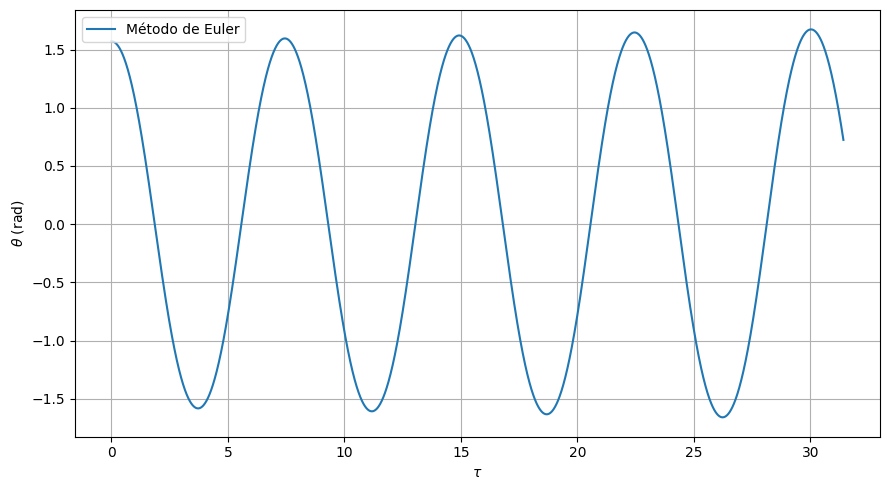

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Lê os dados gerados pelo programa Fortran
dados = np.loadtxt("tarefa-3a-saida-1.dat")

tau = dados[:, 0]
theta = dados[:, 1]
E = dados[:, 2]

# Gráfico do ângulo em função do tempo adimensional
plt.figure(figsize=(9, 5))
plt.plot(tau, theta, label="Método de Euler")
plt.xlabel(r"$\tau$")
plt.ylabel(r"$\theta$ (rad)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

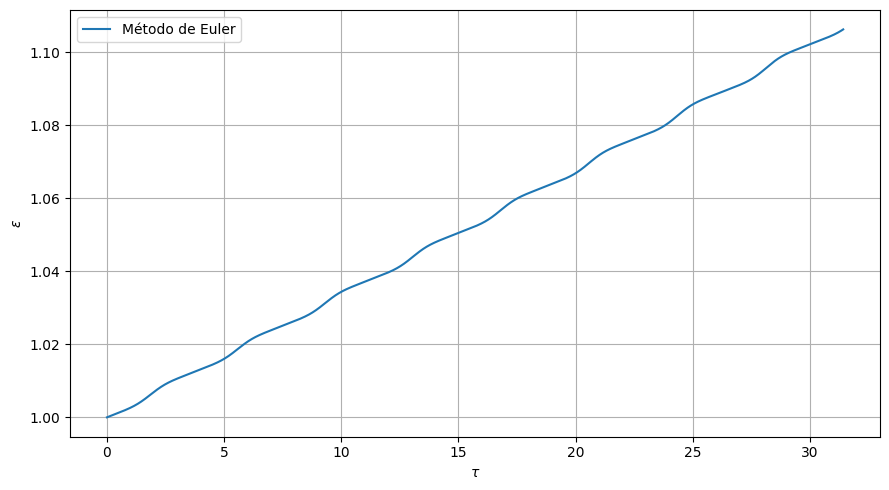

In [ ]:
# Gráfico da energia adimensional em função do tempo
plt.figure(figsize=(9, 5))
plt.plot(tau, E, label=r"Método de Euler")
plt.xlabel(r"$\tau$")
plt.ylabel(r"$\epsilon$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

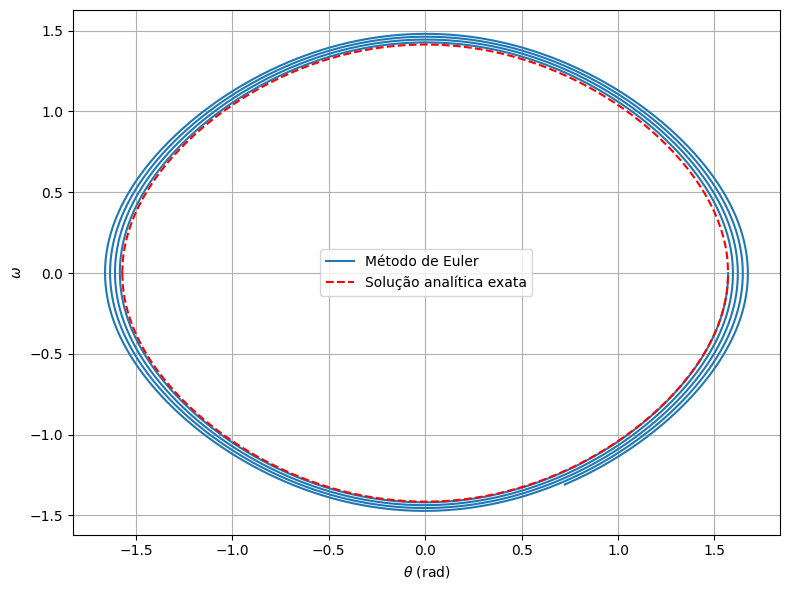

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dados numéricos obtidos pelo Fortran
dados = np.loadtxt("tarefa-3b-saida-1.dat")
theta = dados[:, 0]
omega = dados[:, 1]

# Solução analítica exata
theta_exato = np.linspace(-np.pi/2, np.pi/2, 1000)
omega_exato = np.sqrt(2 * np.cos(theta_exato))

# Gráfico do espaço de fase
plt.figure(figsize=(8, 6))

plt.plot(theta, omega, label="Método de Euler")
plt.plot(theta_exato, omega_exato, "--", color='red',
         label="Solução analítica exata")
plt.plot(theta_exato, -omega_exato, "--", color='red')

plt.xlabel(r"$\theta$ (rad)")
plt.ylabel(r"$\omega$")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

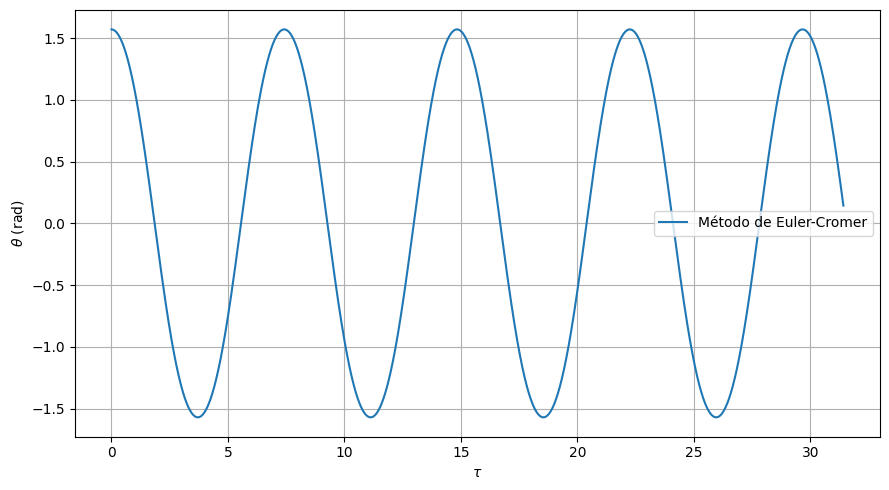

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Lê os dados gerados pelo programa Fortran
dados = np.loadtxt("tarefa-3c-saida-1.dat")

tau = dados[:, 0]
theta = dados[:, 1]
E = dados[:, 2]

# Gráfico do ângulo em função do tempo adimensional
plt.figure(figsize=(9, 5))
plt.plot(tau, theta, label=r"Método de Euler-Cromer")
plt.xlabel(r"$\tau$")
plt.ylabel(r"$\theta$ (rad)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

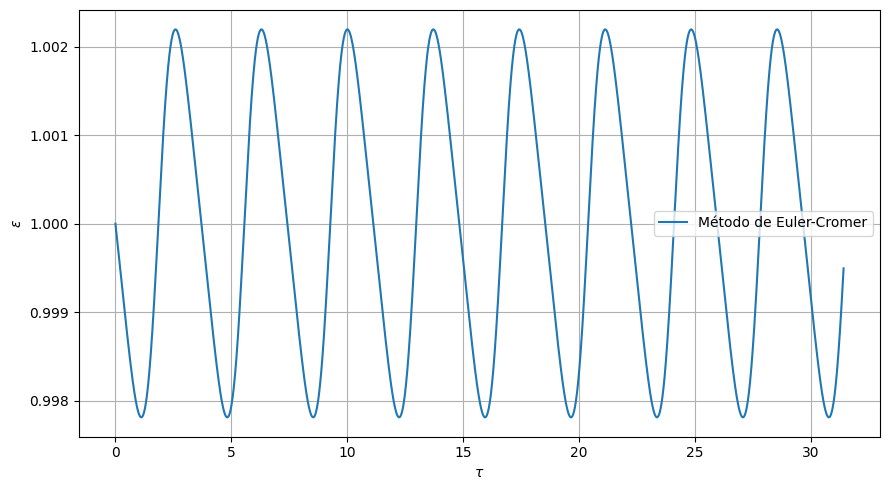

In [ ]:
# Gráfico da energia adimensional em função do tempo
plt.figure(figsize=(9, 5))
plt.plot(tau, E, label=r"Método de Euler-Cromer")
plt.xlabel(r"$\tau$")
plt.ylabel(r"$\epsilon$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

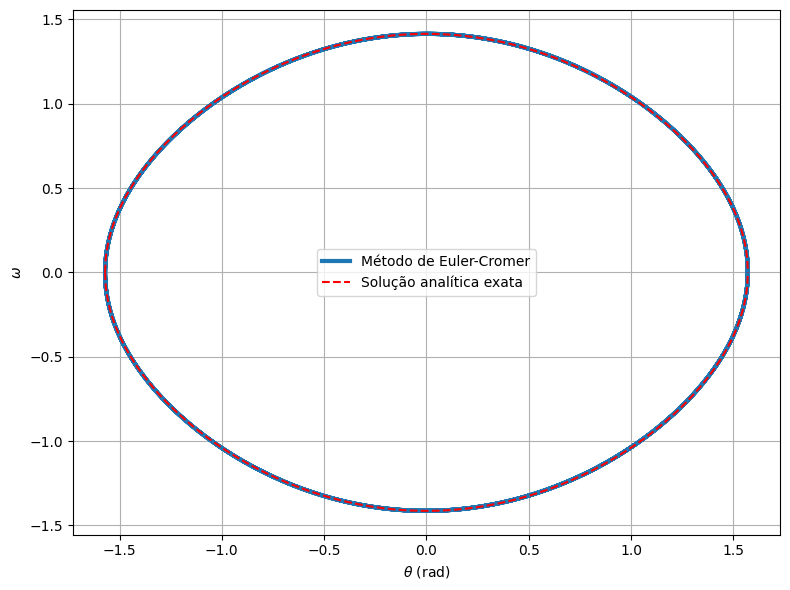

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dados numéricos obtidos pelo Fortran
dados = np.loadtxt("tarefa-3c-saida-2.dat")
theta = dados[:, 0]
omega = dados[:, 1]

# Solução analítica exata
theta_exato = np.linspace(-np.pi/2, np.pi/2, 1000)
omega_exato = np.sqrt(2 * np.cos(theta_exato))

# Gráfico do espaço de fase
plt.figure(figsize=(8, 6))

plt.plot(theta, omega, label="Método de Euler-Cromer", linewidth=3)
plt.plot(theta_exato, omega_exato, "--", color='red',
         label="Solução analítica exata")
plt.plot(theta_exato, -omega_exato, "--", color='red')

plt.xlabel(r"$\theta$ (rad)")
plt.ylabel(r"$\omega$")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

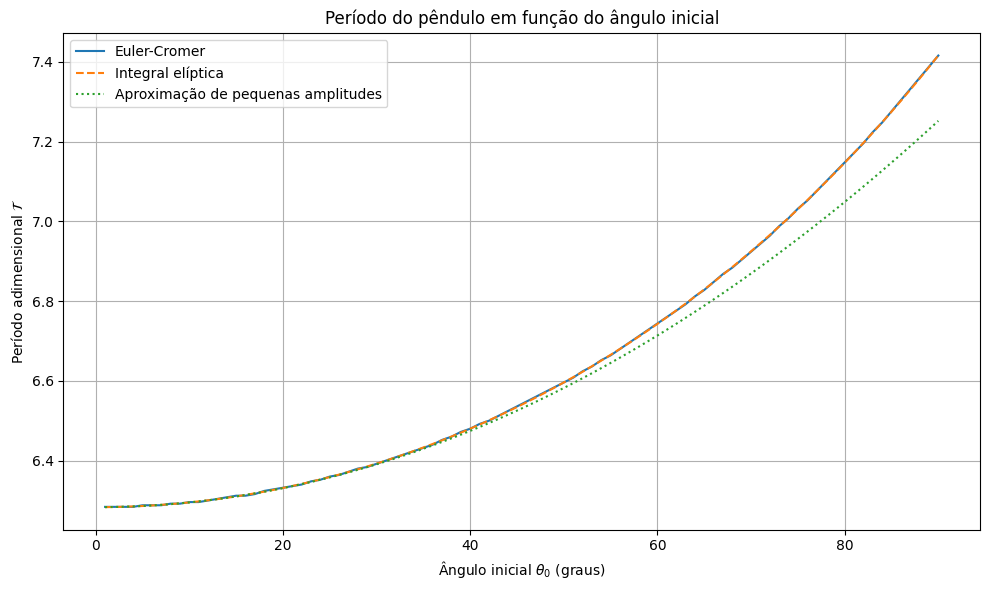

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Leitura dos dados do Fortran
# Colunas: theta0, T_Euler-Cromer, T_integral, T_aproximado
# ============================================================

dados = np.loadtxt("tarefa-3d-saida-1.dat")

theta = np.degrees(dados[:, 0])
T_ec = dados[:, 1]
T_integral = dados[:, 2]
T_aprox = dados[:, 3]

# Evita divisão por zero
erro_relativo = 100 * np.abs(T_ec - T_integral) / T_integral

# ============================================================
# Gráfico 1: Período em função do ângulo inicial
# ============================================================

plt.figure(figsize=(10, 6))
plt.plot(theta, T_ec, label="Euler-Cromer")
plt.plot(theta, T_integral, "--", label="Integral elíptica")
plt.plot(theta, T_aprox, ":", label="Aproximação de pequenas amplitudes")

plt.xlabel(r"Ângulo inicial $\theta_0$ (graus)")
plt.ylabel(r"Período adimensional $\mathcal{T}$")
plt.title("Período do pêndulo em função do ângulo inicial")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Tarefa 4

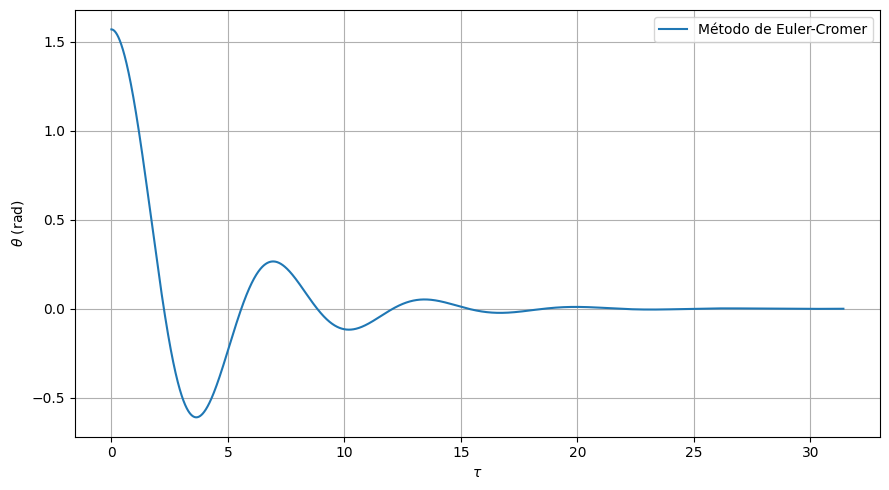

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Lê os dados gerados pelo programa Fortran
dados = np.loadtxt("tarefa-4a-saida-1.dat")

tau = dados[:, 0]
theta = dados[:, 1]

# Gráfico do ângulo em função do tempo adimensional
plt.figure(figsize=(9, 5))
plt.plot(tau, theta, label="Método de Euler-Cromer")
plt.xlabel(r"$\tau$")
plt.ylabel(r"$\theta$ (rad)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Tarefa 5

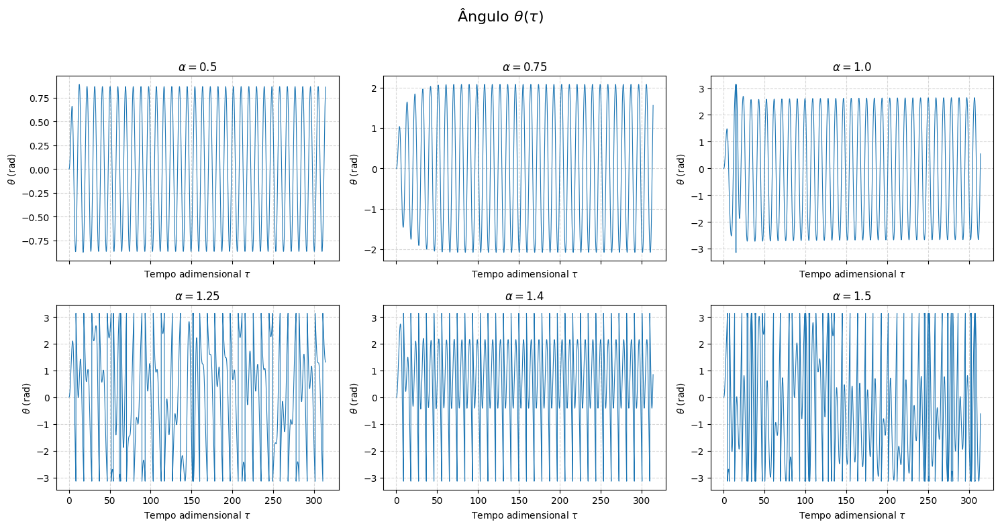

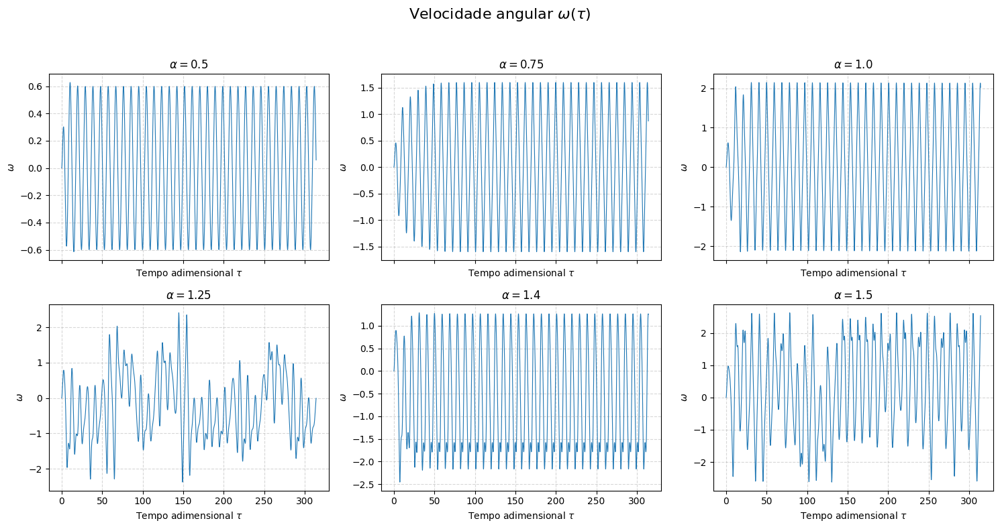

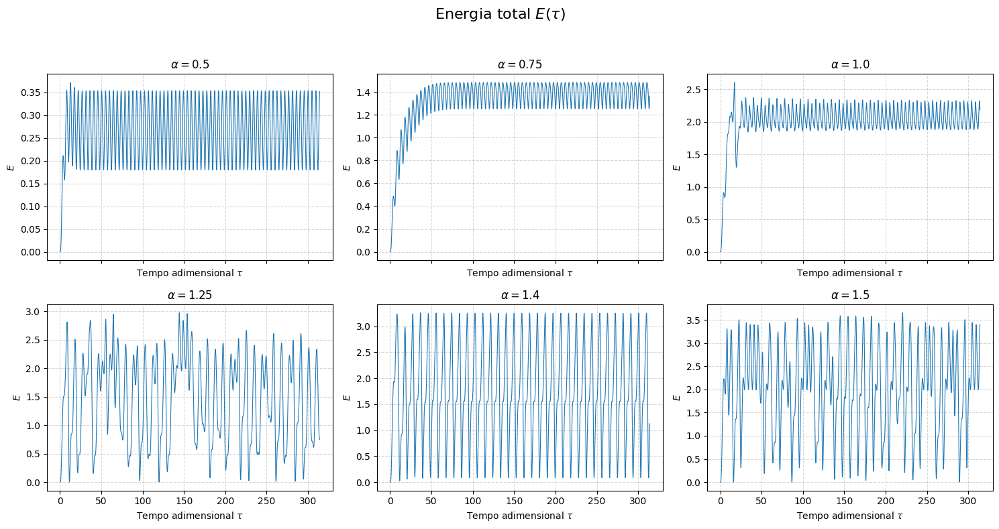

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Valores do parâmetro de força para cada simulação
alphas = [0.5, 0.75, 1.0, 1.25, 1.4, 1.5]

# Nomes dos arquivos de saída do Fortran
arquivos = [
    f"tarefa-5a-saida-{i}.dat"
    for i in range(1, 7)
]

# Carrega os dados de todas as simulações
dados_simulacoes = [
    np.loadtxt(arquivo)
    for arquivo in arquivos
]

# Grandezas: índice da coluna, título, rótulo do eixo y e nome do arquivo
grandezas = [
    (1, r"Ângulo $\theta(\tau)$", r"$\theta$ (rad)", "angulo"),
    (2, r"Velocidade angular $\omega(\tau)$", r"$\omega$", "velocidade"),
    (3, r"Energia total $E(\tau)$", r"$E$", "energia"),
]

# Cria uma figura com 6 subgráficos para cada grandeza
for coluna, titulo, ylabel, nome in grandezas:

    fig, eixos = plt.subplots(
        2, 3,
        figsize=(15, 8),
        sharex=True
    )

    fig.suptitle(titulo, fontsize=16)

    # Percorre os 6 subgráficos e as 6 simulações
    for ax, dados, alpha in zip(
        eixos.flat, dados_simulacoes, alphas
    ):
        tau = dados[:, 0]
        valores = dados[:, coluna]

        ax.plot(tau, valores, linewidth=0.8)

        ax.set_title(rf"$\alpha = {alpha}$")
        ax.set_xlabel(r"Tempo adimensional $\tau$")
        ax.set_ylabel(ylabel)
        ax.grid(True, linestyle="--", alpha=0.5)

    # Ajusta o espaçamento entre os subgráficos
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    plt.show()

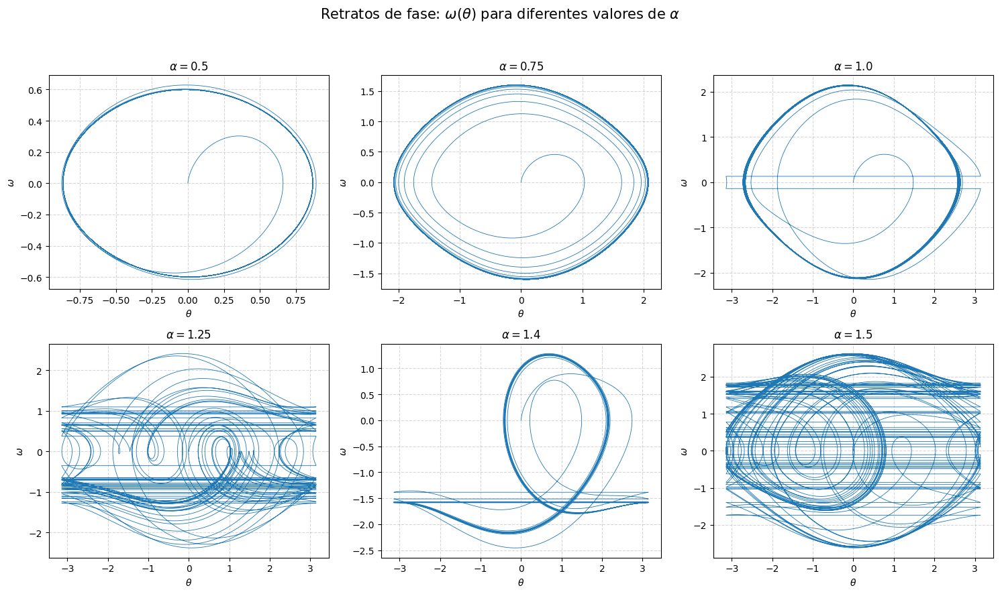

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Valores de alpha em ordem
alphas = [0.5, 0.75, 1.0, 1.25, 1.4, 1.5]

# Arquivos de entrada
arquivos = [
    f"tarefa-5b-saida-{i}.dat"
    for i in range(1, 7)
]

# Cria uma única figura com 6 subgráficos
plt.figure(figsize=(15, 9))

for i, (arquivo, alpha) in enumerate(zip(arquivos, alphas), start=1):
    dados = np.loadtxt(arquivo)

    theta = dados[:, 0]
    omega = dados[:, 1]

    # Posição do gráfico na grade 2 x 3
    plt.subplot(2, 3, i)

    plt.plot(theta, omega, linewidth=0.6)
    plt.title(rf"$\alpha = {alpha}$")
    plt.xlabel(r"$\theta$")
    plt.ylabel(r"$\omega$")
    plt.grid(True, linestyle="--", alpha=0.5)

plt.suptitle(r"Retratos de fase: $\omega(\theta)$ para diferentes valores de $\alpha$",
             fontsize=15)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

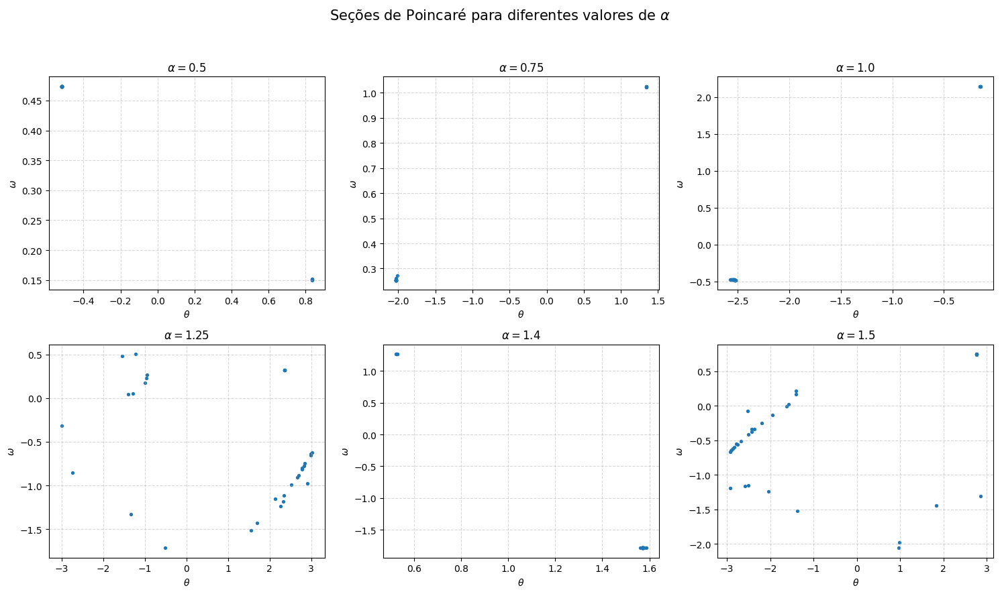

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Valores de alpha em ordem
alphas = [0.5, 0.75, 1.0, 1.25, 1.4, 1.5]

# Arquivos de entrada gerados pelo programa tarefa5c
arquivos = [
    f"tarefa-5c-saida-{i}.dat"
    for i in range(1, 7)
]

# Cria uma única figura com 6 subgráficos
plt.figure(figsize=(15, 9))

for i, (arquivo, alpha) in enumerate(zip(arquivos, alphas), start=1):
    dados = np.loadtxt(arquivo)

    # Colunas: tau, theta, omega
    theta = dados[:, 1]
    omega = dados[:, 2]

    # Posição do gráfico na grade 2 x 3
    plt.subplot(2, 3, i)

    # Seção de Poincaré
    plt.scatter(theta, omega, s=8, marker="o")

    plt.title(rf"$\alpha = {alpha}$")
    plt.xlabel(r"$\theta$")
    plt.ylabel(r"$\omega$")
    plt.grid(True, linestyle="--", alpha=0.5)

plt.suptitle(
    r"Seções de Poincaré para diferentes valores de $\alpha$",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


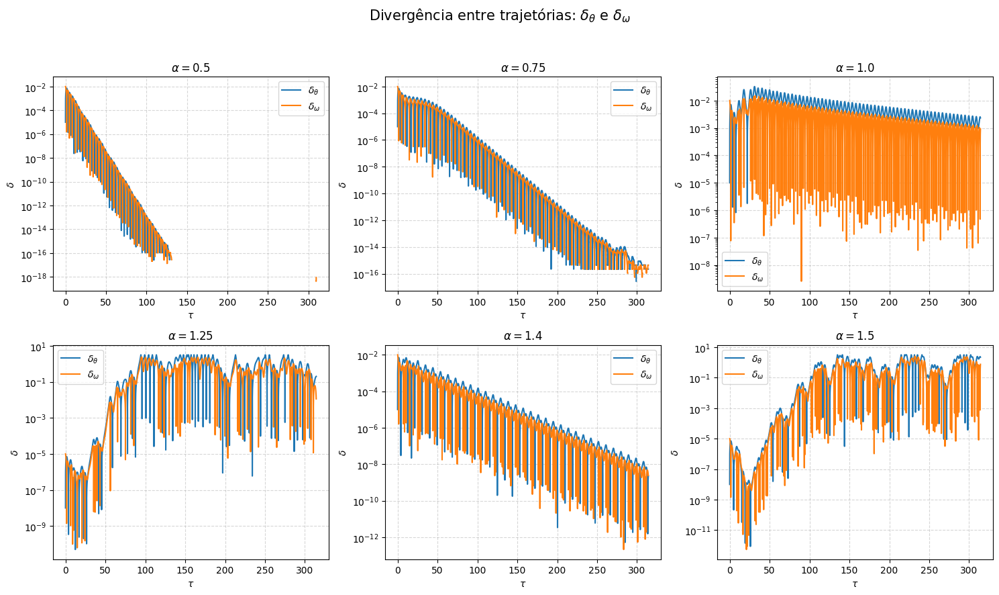

/tmp/ipykernel_2652/2061862574.py:304: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


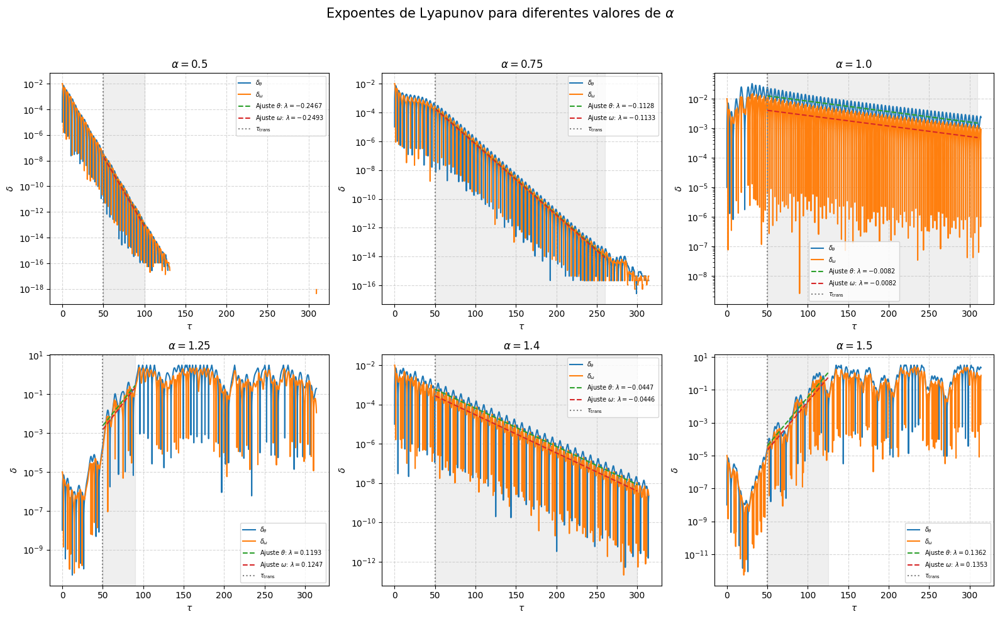



          EXPOENTES DE LYAPUNOV
     alpha     lambda_theta     lambda_omega    Diferenca
----------------------------------------------------------
      0.50        -0.246670        -0.249287     0.002618
      0.75        -0.112838        -0.113267     0.000429
      1.00        -0.008151        -0.008167     0.000016
      1.25         0.119289         0.124668     0.005378
      1.40        -0.044722        -0.044624     0.000098
      1.50         0.136228         0.135319     0.000909


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURACOES
# ============================================================

# Valores de alpha
alphas = [0.5, 0.75, 1.0, 1.25, 1.4, 1.5]

# Arquivos originais do item 5a
arquivos_a = [
    f"tarefa-5a-saida-{i}.dat"
    for i in range(1, 7)
]

# Arquivos perturbados do item 5d
arquivos_d = [
    f"tarefa-5d-saida-{i}.dat"
    for i in range(1, 7)
]

# Diferenca minima considerada no ajuste.
# Evita problemas numericos quando as trajetorias convergem.
DELTA_MIN = 1e-14


# ============================================================
# LEITURA DOS ARQUIVOS
# ============================================================

def carregar_dados(arquivo):
    dados = np.loadtxt(arquivo)
    dados = np.atleast_2d(dados)

    if dados.shape[1] < 3:
        raise ValueError(
            f"O arquivo {arquivo} deve ter pelo menos 3 colunas."
        )

    tau = dados[:, 0]
    theta = dados[:, 1]
    omega = dados[:, 2]

    if not np.all(np.diff(tau) > 0):
        raise ValueError(
            f"Os tempos em {arquivo} nao estao em ordem crescente."
        )

    return tau, theta, omega


# ============================================================
# CALCULO DAS DIFERENCAS ENTRE AS TRAJETORIAS
# ============================================================

resultados = []

for alpha, arquivo_a, arquivo_d in zip(
    alphas, arquivos_a, arquivos_d
):

    tau_a, theta, omega = carregar_dados(arquivo_a)
    tau_d, theta_new, omega_new = carregar_dados(arquivo_d)

    # Verifica se as trajetorias possuem os mesmos instantes
    if np.array_equal(tau_a, tau_d):
        theta_new_interp = theta_new
        omega_new_interp = omega_new

    else:
        # Interpola a nova trajetoria nos tempos da original
        if tau_a[0] < tau_d[0] or tau_a[-1] > tau_d[-1]:
            raise ValueError(
                f"Os arquivos para alpha={alpha} possuem "
                "intervalos de tempo incompatíveis."
            )

        # Desembrulha theta antes da interpolacao
        theta_new_unwrapped = np.unwrap(theta_new)

        theta_new_interp = np.interp(
            tau_a, tau_d, theta_new_unwrapped
        )

        omega_new_interp = np.interp(
            tau_a, tau_d, omega_new
        )

    # Diferenca angular minima, evitando saltos artificiais
    # na passagem de +pi para -pi
    diferenca_theta = theta - theta_new_interp

    delta_theta = np.abs(
        np.arctan2(
            np.sin(diferenca_theta),
            np.cos(diferenca_theta)
        )
    )

    # Diferenca entre as velocidades angulares
    delta_omega = np.abs(omega - omega_new_interp)

    resultados.append({
        "alpha": alpha,
        "tau": tau_a,
        "delta_theta": delta_theta,
        "delta_omega": delta_omega
    })


# ============================================================
# GRAFICOS PRELIMINARES DAS DIFERENCAS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, resultado in zip(axes.flat, resultados):

    tau = resultado["tau"]
    delta_theta = resultado["delta_theta"]
    delta_omega = resultado["delta_omega"]
    alpha = resultado["alpha"]

    # Evita representar valores nulos na escala logaritmica
    dt_plot = np.where(delta_theta > 0, delta_theta, np.nan)
    dw_plot = np.where(delta_omega > 0, delta_omega, np.nan)

    ax.semilogy(
        tau, dt_plot,
        label=r"$\delta_\theta$"
    )

    ax.semilogy(
        tau, dw_plot,
        label=r"$\delta_\omega$"
    )

    ax.set_title(rf"$\alpha = {alpha}$")
    ax.set_xlabel(r"$\tau$")
    ax.set_ylabel(r"$\delta$")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

fig.suptitle(
    r"Divergência entre trajetórias: $\delta_\theta$ e $\delta_\omega$",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# ============================================================
# DEFINICAO DAS JANELAS DE AJUSTE
# ============================================================

# Tempo de transiente fixado
tau_trans = [50.0] * len(alphas)

# Instantes finais estimados visualmente
tau_fit_fim = [
    100.0,
    260.0,
    310.0,
    90.0,
    300.0,
    125.0
]

# ============================================================
# AJUSTE EXPONENCIAL E CALCULO DOS EXPOENTES
# ============================================================

def calcula_lyapunov(tau, delta, t_inicio, t_fim):

    # Seleciona o intervalo de ajuste e elimina valores
    # nulos ou muito pequenos
    mascara = (
        (tau >= t_inicio) &
        (tau <= t_fim) &
        (delta > DELTA_MIN) &
        np.isfinite(delta)
    )

    tau_fit = tau[mascara]
    delta_fit = delta[mascara]

    if len(tau_fit) < 3:
        raise ValueError(
            "Poucos pontos validos na janela de ajuste."
        )

    # Ajuste linear:
    # ln(delta) = lambda*tau + constante
    coeficientes = np.polyfit(
        tau_fit,
        np.log(delta_fit),
        1
    )

    lamb = coeficientes[0]
    constante = coeficientes[1]

    # Curva exponencial ajustada
    delta_ajustado = np.exp(
        lamb * tau_fit + constante
    )

    return lamb, tau_fit, delta_ajustado


# ============================================================
# GRAFICOS FINAIS E TABELA
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

lambda_theta = []
lambda_omega = []

for i, (ax, resultado) in enumerate(
    zip(axes.flat, resultados)
):

    alpha = resultado["alpha"]
    tau = resultado["tau"]

    dt = resultado["delta_theta"]
    dw = resultado["delta_omega"]

    t_trans = tau_trans[i]
    t_fim = tau_fit_fim[i]

    # Calcula os expoentes de Lyapunov
    lt, tau_fit_t, ajuste_t = calcula_lyapunov(
        tau, dt, t_trans, t_fim
    )

    lw, tau_fit_w, ajuste_w = calcula_lyapunov(
        tau, dw, t_trans, t_fim
    )

    lambda_theta.append(lt)
    lambda_omega.append(lw)

    # Dados originais
    ax.semilogy(
        tau,
        np.where(dt > 0, dt, np.nan),
        label=r"$\delta_\theta$"
    )

    ax.semilogy(
        tau,
        np.where(dw > 0, dw, np.nan),
        label=r"$\delta_\omega$"
    )

    # Ajustes exponenciais
    ax.semilogy(
        tau_fit_t,
        ajuste_t,
        "--",
        linewidth=1.5,
        label=rf"Ajuste $\theta$: $\lambda={lt:.4f}$"
    )

    ax.semilogy(
        tau_fit_w,
        ajuste_w,
        "--",
        linewidth=1.5,
        label=rf"Ajuste $\omega$: $\lambda={lw:.4f}$"
    )

    # Indicacao do transiente e da janela de ajuste
    ax.axvline(
        t_trans,
        color="gray",
        linestyle=":",
        label=r"$\tau_{\mathrm{trans}}$"
    )

    ax.axvspan(
        t_trans,
        t_fim,
        color="gray",
        alpha=0.12
    )

    ax.set_title(rf"$\alpha = {alpha}$")
    ax.set_xlabel(r"$\tau$")
    ax.set_ylabel(r"$\delta$")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=7)

fig.suptitle(
    r"Expoentes de Lyapunov para diferentes valores de $\alpha$",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(
    "tarefa-5d-expoentes-lyapunov.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ============================================================
# TABELA DOS EXPOENTES DE LYAPUNOV
# ============================================================

print("\n")
print("=" * 58)
print("          EXPOENTES DE LYAPUNOV")
print("=" * 58)

print(
    f"{'alpha':>10} {'lambda_theta':>16} "
    f"{'lambda_omega':>16} {'Diferenca':>12}"
)

print("-" * 58)

for alpha, lt, lw in zip(
    alphas, lambda_theta, lambda_omega
):

    diferenca = abs(lt - lw)

    print(
        f"{alpha:10.2f} {lt:16.6f} "
        f"{lw:16.6f} {diferenca:12.6f}"
    )

print("=" * 58)


### Tarefa 6

Frequencia critica aproximada: nu* = 15.000000


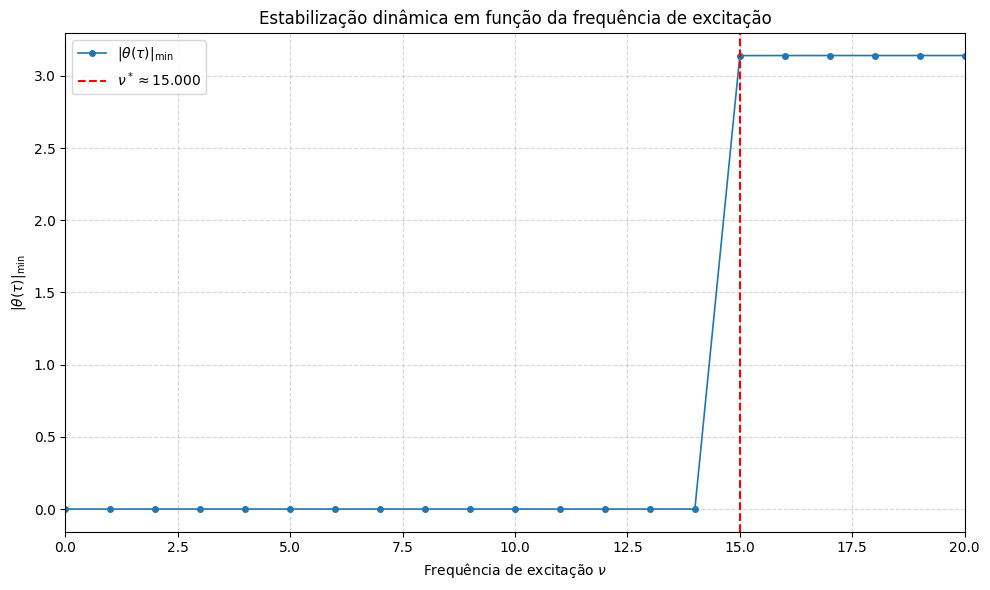

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LEITURA DOS DADOS
# ============================================================

arquivo = "tarefa-6a-saida-1.dat"

dados = np.loadtxt(arquivo)

nu = dados[:, 0]
theta_min = dados[:, 1]

# Ordena os dados em ordem crescente de frequencia
ordem = np.argsort(nu)
nu = nu[ordem]
theta_min = theta_min[ordem]

# ============================================================
# IDENTIFICACAO DA FREQUENCIA CRITICA
# ============================================================

# Tolerancia numerica para considerar theta_min diferente de zero
tolerancia = 1e-3

indices = np.where(theta_min > tolerancia)[0]

if len(indices) > 0:
    nu_critica = nu[indices[0]]
    print(f"Frequencia critica aproximada: nu* = {nu_critica:.6f}")
else:
    nu_critica = None
    print("Nao foi identificada estabilizacao dinamica.")

# ============================================================
# GRAFICO
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    nu,
    theta_min,
    "o-",
    markersize=4,
    linewidth=1.2,
    label=r"$|\theta(\tau)|_{\min}$"
)

if nu_critica is not None:
    plt.axvline(
        nu_critica,
        color="red",
        linestyle="--",
        label=rf"$\nu^* \approx {nu_critica:.3f}$"
    )

plt.xlabel(r"Frequência de excitação $\nu$")
plt.ylabel(r"$|\theta(\tau)|_{\min}$")
plt.title(
    r"Estabilização dinâmica em função da frequência de excitação"
)

plt.xlim(0, 20)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.savefig("tarefa-6a-grafico.png", dpi=300)
plt.show()


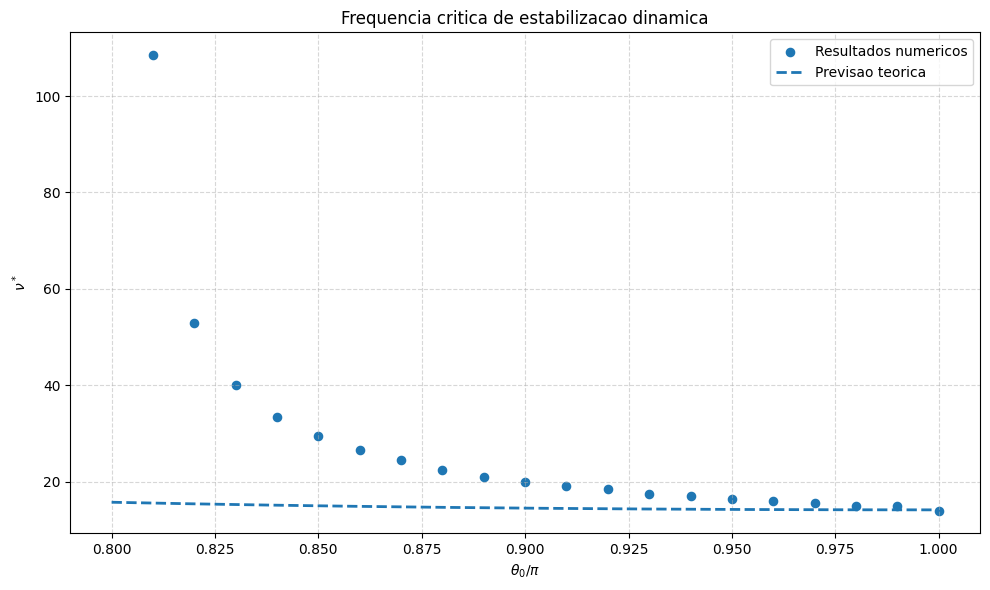

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURACOES
# ============================================================

arquivo = "tarefa-6b-saida-1.dat"
alpha = 0.1

# ============================================================
# LEITURA DOS DADOS
# ============================================================

dados = np.loadtxt(arquivo)

theta0 = dados[:, 0]
nu_star = dados[:, 1]

# Remove resultados sem estabilizacao (nu* = -1)
mascara = nu_star > 0

theta_validos = theta0[mascara]
nu_validos = nu_star[mascara]

# ============================================================
# PREVISAO TEORICA
# ============================================================

theta_teorico = np.linspace(
    0.8*np.pi + 1e-5,
    np.pi - 1e-5,
    500
)

nu_teorico = np.sqrt(
    -2.0 / (alpha**2 * np.cos(theta_teorico))
)

# ============================================================
# GRAFICO
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    theta_validos / np.pi,
    nu_validos,
    s=35,
    label="Resultados numericos"
)

plt.plot(
    theta_teorico / np.pi,
    nu_teorico,
    "--",
    linewidth=2,
    label="Previsao teorica"
)

plt.xlabel(r"$\theta_0/\pi$")
plt.ylabel(r"$\nu^*$")

plt.title(
    r"Frequencia critica de estabilizacao dinamica"
)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()

plt.show()



ESTIMATIVAS TEORICAS
--------------------
omega_s = 2.64575131
omega_f = 40.00000000


PARAMETROS OBTIDOS PELO AJUSTE DOS DADOS

A_s (theta_0 da expressao) = 5.7541442939e-04 rad
gamma                   = 0.0500009030
omega_s                 = 2.6661494804
omega_f                 = 39.9999794287
delta                   = 0.1013528135
phi_s                   = -0.5917880965 rad
phi_f                   = 0.0008305933 rad

Fases em graus:
phi_s = -33.906960 graus
phi_f = 0.047589 graus


VERIFICACAO DAS APROXIMACOES TEORICAS

omega_s ajustada = 2.66614948
omega_s teorica  = 2.64575131
Erro relativo omega_s = 0.7710%

omega_f ajustada = 39.99997943
nu                = 40.00000000
Erro relativo omega_f = 0.0001%

Delta = 0.101353
A modulacao rapida possui amplitude pequena em relacao a 1.

RMSE = 1.2722965764e-06 rad
R²   = 0.9999075212

Grafico salvo em: /content/tarefa-6c-saida-1_analise.png


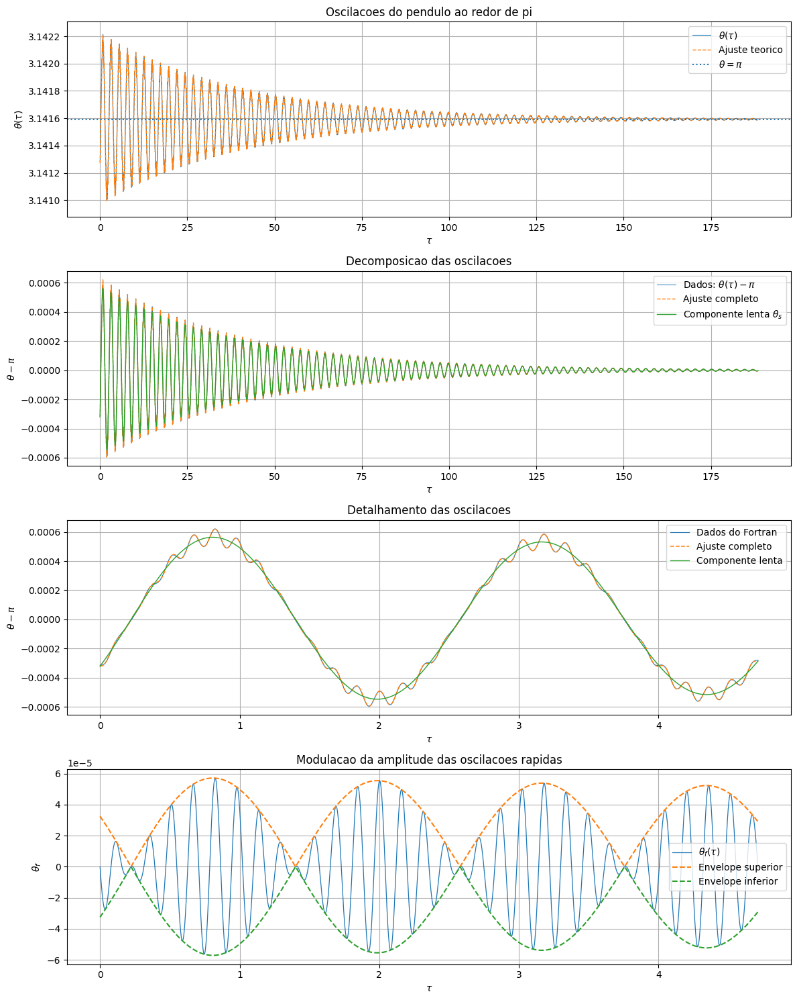

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import least_squares
from pathlib import Path
import argparse

# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

parser = argparse.ArgumentParser(
    description="Analise do pendulo de Kapitza - tarefa 6c"
)

parser.add_argument(
    "arquivo",
    nargs="?",
    default="/content/tarefa-6c-saida-1.dat",
    help="Arquivo .dat produzido pelo Fortran"
)

parser.add_argument("--alpha", type=float, default=0.1)
parser.add_argument("--nu", type=float, default=40.0)
parser.add_argument(
    "--gamma",
    type=float,
    default=0.05,
    help="Valor de gamma usado apenas como chute inicial do ajuste"
)

# Filtra e remove argumentos internos do Colab/Jupyter para evitar conflitos
args, unknown = parser.parse_known_args()

# Se o argumento posicional 'arquivo' capturou por engano o JSON do kernel, forçamos o padrão correto
if args.arquivo and args.arquivo.endswith(".json"):
    arquivo = "/content/tarefa-6c-saida-1.dat"
else:
    arquivo = args.arquivo

alpha = args.alpha
nu = args.nu
gamma_inicial = args.gamma

pi = np.pi

# ============================================================
# 2. LEITURA DOS DADOS DO FORTRAN
# ============================================================

dados = np.loadtxt(arquivo, ndmin=2)

if dados.shape[1] < 2:
    raise ValueError("O arquivo deve conter pelo menos duas colunas.")

tau = dados[:, 0]
theta = dados[:, 1]

# Pega ordem crescente do tempo
ordem = np.argsort(tau)
tau = tau[ordem]
theta = theta[ordem]

# Remove eventuais tempos duplicados
indices_validos = np.r_[True, np.diff(tau) > 0]

tau = tau[indices_validos]
theta = theta[indices_validos]

if len(tau) < 100:
    raise ValueError("Quantidade insuficiente de dados.")

# Corrige eventuais descontinuidades de 2*pi
theta = np.unwrap(theta)

# Componente em torno da posição invertida
y = theta - pi

# Normalização para melhorar a estabilidade numérica do ajuste
escala = np.max(np.abs(y))

if escala == 0:
    raise ValueError("O sinal theta - pi é identicamente nulo.")

y_normalizado = y / escala

# ============================================================
# 3. ESTIMATIVAS TEÓRICAS PARA INICIALIZAR O AJUSTE
# ============================================================

# Frequência lenta prevista pela aproximação do potencial efetivo
argumento = (alpha * nu)**2 / 2.0 - 1.0

if argumento <= 0:
    raise ValueError(
        "O sistema nao esta na regiao de estabilidade prevista "
        "pela aproximacao de Kapitza."
    )

omega_s_teorico = np.sqrt(argumento)

# Frequência rápida aproximadamente igual à frequência externa
omega_f_teorico = nu

print("\nESTIMATIVAS TEORICAS")
print("--------------------")
print(f"omega_s = {omega_s_teorico:.8f}")
print(f"omega_f = {omega_f_teorico:.8f}")

# ============================================================
# 4. MODELO MATEMÁTICO DO AJUSTE
# ============================================================

def modelo(parametros, t):
    A, gamma, omega_s, omega_f, delta, phi_s, phi_f = parametros
    envelope = np.exp(-gamma * t / 2.0)
    oscilacao_lenta = np.sin(omega_s * t + phi_s)
    modulacao_rapida = (
        1.0 + delta * np.sin(omega_f * t + phi_f)
    )
    return (
        A
        * envelope
        * oscilacao_lenta
        * modulacao_rapida
    )

# ============================================================
# 5. AJUSTE POR MÍNIMOS QUADRADOS
# ============================================================

n_fit = min(len(tau), 40000)

indices_fit = np.linspace(
    0, len(tau) - 1, n_fit, dtype=int
)

tau_fit = tau[indices_fit]
y_fit = y_normalizado[indices_fit]

# Chutes iniciais dos parâmetros
delta_inicial = np.clip(alpha, 0.01, 0.4)

phi_s_inicial = -np.arctan2(
    omega_s_teorico,
    delta_inicial * nu - gamma_inicial / 2.0
)

phi_f_inicial = 0.0

p0 = [
    1.0,
    gamma_inicial,
    omega_s_teorico,
    nu,
    delta_inicial,
    phi_s_inicial,
    phi_f_inicial
]

limites_inferiores = [
    0.0,
    0.0,
    0.5 * omega_s_teorico,
    0.7 * nu,
    0.0,
    -2.0 * pi,
    -2.0 * pi
]

limites_superiores = [
    10.0,
    0.5,
    1.5 * omega_s_teorico,
    1.3 * nu,
    0.5,
    2.0 * pi,
    2.0 * pi
]

def residuo(parametros):
    return (
        modelo(parametros, tau_fit)
        - y_fit
    )

resultado = least_squares(
    residuo,
    p0,
    bounds=(
        limites_inferiores,
        limites_superiores
    ),
    method="trf",
    x_scale="jac",
    max_nfev=1000,
    ftol=1e-10,
    xtol=1e-10,
    gtol=1e-10
)

if not resultado.success:
    print("\nATENCAO: o otimizador nao confirmou convergencia.")
    print(resultado.message)

# ============================================================
# 6. EXTRAÇÃO DOS PARÂMETROS FÍSICOS
# ============================================================

A_normalizado, gamma, omega_s, omega_f, delta, phi_s, phi_f = (
    resultado.x
)

# Recupera a amplitude na escala original
A = A_normalizado * escala

# Normaliza as fases para o intervalo [-pi, pi)
def normaliza_fase(phi):
    return (phi + pi) % (2.0 * pi) - pi

phi_s = normaliza_fase(phi_s)
phi_f = normaliza_fase(phi_f)

# ============================================================
# 7. RECONSTRUÇÃO DAS COMPONENTES LENTA E RÁPIDA
# ============================================================

envelope = A * np.exp(-gamma * tau / 2.0)

theta_lenta = (
    envelope
    * np.sin(omega_s * tau + phi_s)
)

theta_rapida = (
    theta_lenta
    * delta
    * np.sin(omega_f * tau + phi_f)
)

theta_ajustada = theta_lenta + theta_rapida

# ============================================================
# 8. QUALIDADE DO AJUSTE
# ============================================================

residuos = y - theta_ajustada

rmse = np.sqrt(np.mean(residuos**2))

soma_quadrados = np.sum((y - theta_ajustada)**2)

soma_total = np.sum((y - np.mean(y))**2)

R2 = 1.0 - soma_quadrados / soma_total

# ============================================================
# 9. RESULTADOS NUMÉRICOS
# ============================================================

print("\n")
print("=" * 60)
print("PARAMETROS OBTIDOS PELO AJUSTE DOS DADOS")
print("=" * 60)

print(f"\nA_s (theta_0 da expressao) = {A:.10e} rad")
print(f"gamma                   = {gamma:.10f}")
print(f"omega_s                 = {omega_s:.10f}")
print(f"omega_f                 = {omega_f:.10f}")
print(f"delta                   = {delta:.10f}")
print(f"phi_s                   = {phi_s:.10f} rad")
print(f"phi_f                   = {phi_f:.10f} rad")

print("\nFases em graus:")
print(f"phi_s = {np.degrees(phi_s):.6f} graus")
print(f"phi_f = {np.degrees(phi_f):.6f} graus")

print("\n")
print("=" * 60)
print("VERIFICACAO DAS APROXIMACOES TEORICAS")
print("=" * 60)

print(f"\nomega_s ajustada = {omega_s:.8f}")
print(f"omega_s teorica  = {omega_s_teorico:.8f}")
print(
    f"Erro relativo omega_s = "
    f"{abs(omega_s - omega_s_teorico) / omega_s_teorico * 100:.4f}%"
)

print(f"\nomega_f ajustada = {omega_f:.8f}")
print(f"nu                = {nu:.8f}")
print(
    f"Erro relativo omega_f = "
    f"{abs(omega_f - nu) / nu * 100:.4f}%"
)

print(f"\nDelta = {delta:.6f}")

if delta < 0.2:
    print("A modulacao rapida possui amplitude pequena em relacao a 1.")
else:
    print("A modulacao rapida nao e desprezivel.")

print(f"\nRMSE = {rmse:.10e} rad")
print(f"R²   = {R2:.10f}")

# ============================================================
# 10. GRÁFICOS
# ============================================================

n_plot = min(len(tau), 30000)

indices_plot = np.linspace(
    0, len(tau) - 1, n_plot, dtype=int
)

t_plot = tau[indices_plot]

fig, axs = plt.subplots(
    4, 1,
    figsize=(12, 15)
)

# Gráfico 1: theta(tau) em todo o intervalo
axs[0].plot(
    t_plot,
    theta[indices_plot],
    label=r"$\theta(\tau)$",
    linewidth=0.8
)

axs[0].plot(
    t_plot,
    pi + theta_ajustada[indices_plot],
    "--",
    label="Ajuste teorico",
    linewidth=1.0
)

axs[0].axhline(
    pi,
    linestyle=":",
    label=r"$\theta=\pi$"
)

amplitude_maxima = 1.15 * np.max(np.abs(y))

axs[0].set_ylim(
    pi - amplitude_maxima,
    pi + amplitude_maxima
)

axs[0].set_xlabel(r"$\tau$")
axs[0].set_ylabel(r"$\theta(\tau)$")
axs[0].set_title("Oscilacoes do pendulo ao redor de pi")
axs[0].legend()
axs[0].grid()

# Gráfico 2: sinal completo e ajuste em todo o intervalo
axs[1].plot(
    t_plot,
    y[indices_plot],
    label=r"Dados: $\theta(\tau)-\pi$",
    linewidth=0.7
)

axs[1].plot(
    t_plot,
    theta_ajustada[indices_plot],
    "--",
    label="Ajuste completo",
    linewidth=1.0
)

axs[1].plot(
    t_plot,
    theta_lenta[indices_plot],
    label=r"Componente lenta $\theta_s$",
    linewidth=1.0
)

axs[1].set_xlabel(r"$\tau$")
axs[1].set_ylabel(r"$\theta-\pi$")
axs[1].set_title("Decomposicao das oscilacoes")
axs[1].legend()
axs[1].grid()

# Gráfico 3: aproximação das oscilações rápidas
tau_zoom = min(
    2.0 * 2.0 * pi / omega_s,
    tau[-1]
)

mask = tau <= tau_zoom

axs[2].plot(
    tau[mask],
    y[mask],
    label="Dados do Fortran",
    linewidth=0.8
)

axs[2].plot(
    tau[mask],
    theta_ajustada[mask],
    "--",
    label="Ajuste completo",
    linewidth=1.1
)

axs[2].plot(
    tau[mask],
    theta_lenta[mask],
    label="Componente lenta",
    linewidth=1.0
)

axs[2].set_xlabel(r"$\tau$")
axs[2].set_ylabel(r"$\theta-\pi$")
axs[2].set_title("Detalhamento das oscilacoes")
axs[2].legend()
axs[2].grid()

# Gráfico 4: componente rápida e sua modulação
amplitude_rapida = delta * np.abs(theta_lenta)

axs[3].plot(
    tau[mask],
    theta_rapida[mask],
    label=r"$\theta_f(\tau)$",
    linewidth=0.9
)

axs[3].plot(
    tau[mask],
    amplitude_rapida[mask],
    "--",
    label="Envelope superior",
)

axs[3].plot(
    tau[mask],
    -amplitude_rapida[mask],
    "--",
    label="Envelope inferior",
)

axs[3].set_xlabel(r"$\tau$")
axs[3].set_ylabel(r"$\theta_f$")
axs[3].set_title("Modulacao da amplitude das oscilacoes rapidas")
axs[3].legend()
axs[3].grid()

plt.tight_layout()

# Salva a figura automaticamente
caminho_png = (
    Path(arquivo).parent
    / (Path(arquivo).stem + "_analise.png")
)

plt.savefig(
    caminho_png,
    dpi=200,
    bbox_inches="tight"
)

print(f"\nGrafico salvo em: {caminho_png}")

plt.show()

## Projeto 5

### Tarefa 1

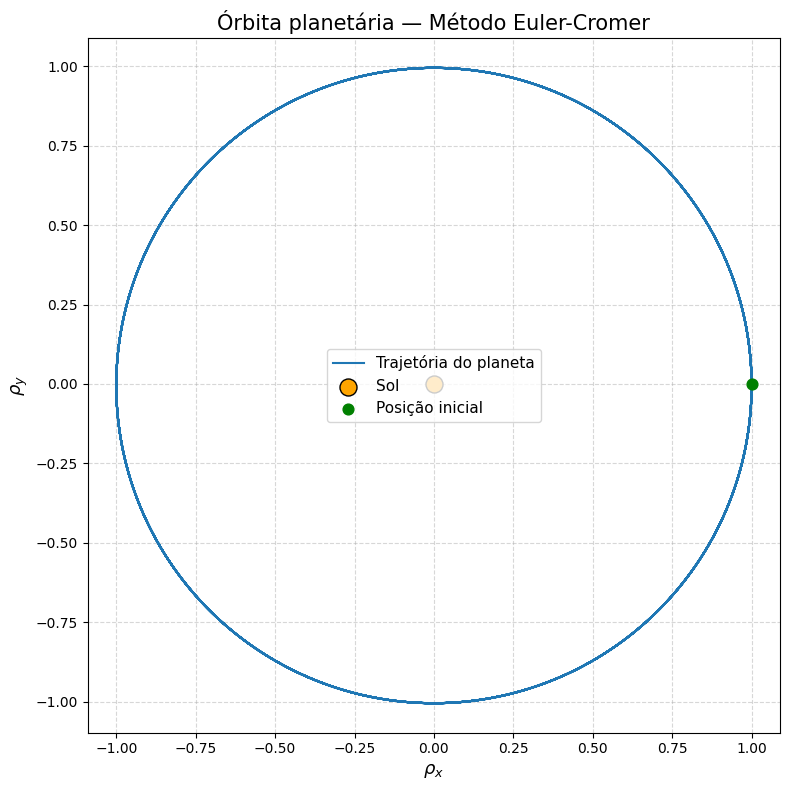

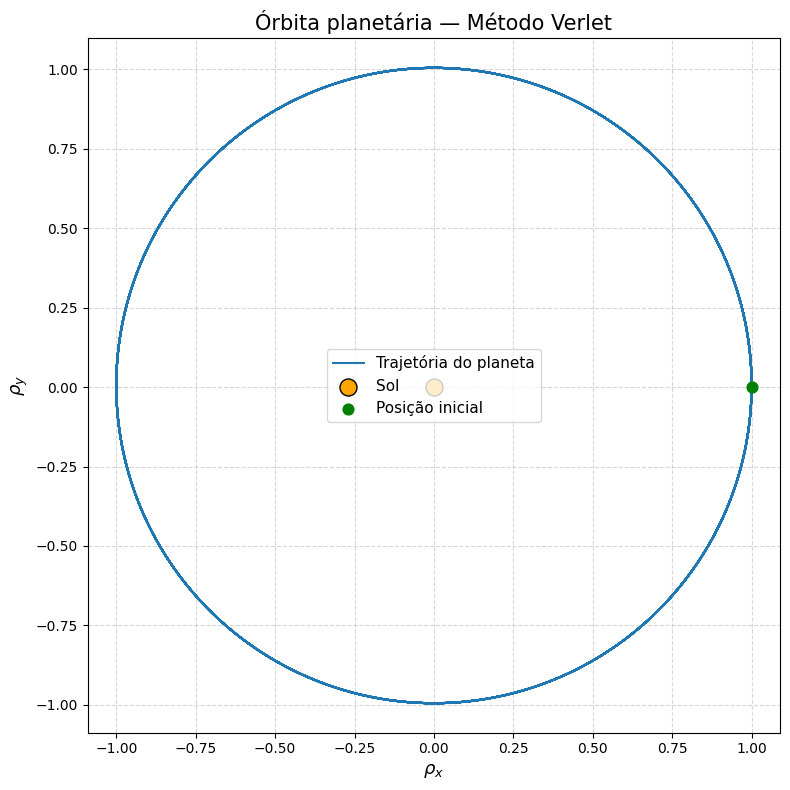

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbita(arquivo, metodo):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]
    rx = dados[:, 1]
    ry = dados[:, 2]

    # Construção do gráfico
    fig, ax = plt.subplots(figsize=(8, 8))

    ax.plot(rx, ry, linewidth=1.5, label='Trajetória do planeta')

    # Representação do Sol na origem
    ax.scatter(0, 0, color='orange', s=150,
               marker='o', edgecolors='black', label='Sol', zorder=5)

    # Posição inicial do planeta
    ax.scatter(rx[0], ry[0], color='green', s=60,
               label='Posição inicial', zorder=5)

    ax.set_xlabel(r'$\rho_x$', fontsize=13)
    ax.set_ylabel(r'$\rho_y$', fontsize=13)
    ax.set_title(f'Órbita planetária — Método {metodo}', fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()


# Euler-Cromer
plot_orbita(
    'tarefa1b-saida-1.dat',
    'Euler-Cromer'
)

# Verlet
plot_orbita(
    'tarefa1b-saida-2.dat',
    'Verlet'
)

Coeficiente C (Euler-Cromer): 9.99500304e-04
Coeficiente C (Verlet):      9.99500299e-04


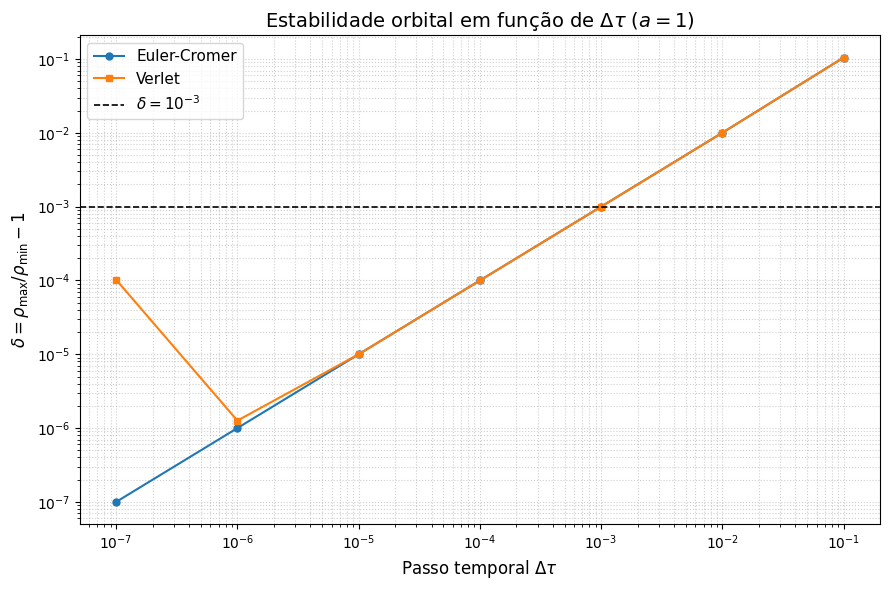

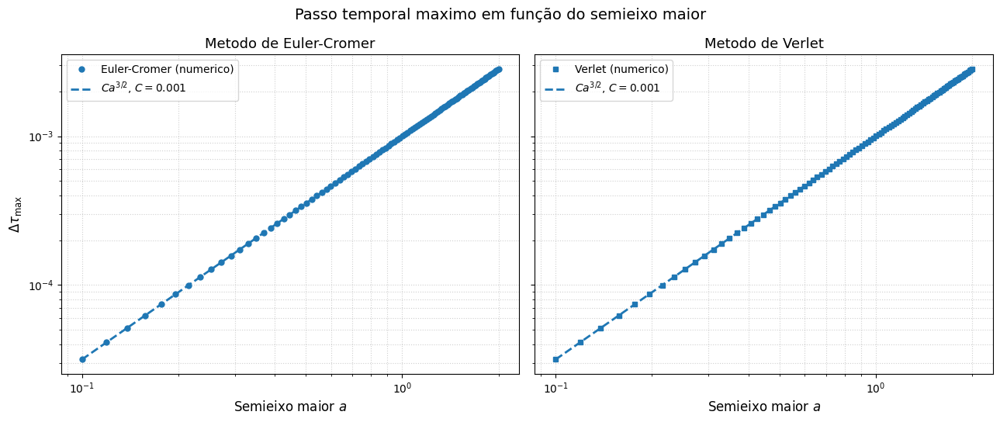

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Leitura dos arquivos
# ============================================================

# Arquivos 1 e 2: delta em funcao de dtau
dtau_ec, delta_ec = np.loadtxt(
    'tarefa1c-saida-1.dat', unpack=True
)

dtau_v, delta_v = np.loadtxt(
    'tarefa1c-saida-2.dat', unpack=True
)

# Arquivos 3 e 4: dtau_max em funcao de a
a_ec, dtau_max_ec = np.loadtxt(
    'tarefa1c-saida-3.dat', unpack=True
)

a_v, dtau_max_v = np.loadtxt(
    'tarefa1c-saida-4.dat', unpack=True
)


# ============================================================
# Grafico 1: delta em funcao de dtau
# ============================================================

fig1, ax1 = plt.subplots(figsize=(9, 6))

# Ordenacao dos dados
ordem_ec = np.argsort(dtau_ec)
ordem_v = np.argsort(dtau_v)

# Valores positivos para escala logaritmica
mask_ec = (dtau_ec > 0) & (delta_ec > 0)
mask_v = (dtau_v > 0) & (delta_v > 0)

ax1.loglog(
    dtau_ec[mask_ec],
    delta_ec[mask_ec],
    'o-',
    markersize=5,
    label='Euler-Cromer'
)

ax1.loglog(
    dtau_v[mask_v],
    delta_v[mask_v],
    's-',
    markersize=5,
    label='Verlet'
)

# Criterio de estabilidade
ax1.axhline(
    y=1e-3,
    color='black',
    linestyle='--',
    linewidth=1.2,
    label=r'$\delta = 10^{-3}$'
)

ax1.set_xlabel(r'Passo temporal $\Delta\tau$', fontsize=12)
ax1.set_ylabel(r'$\delta = \rho_{\max}/\rho_{\min}-1$', fontsize=12)

ax1.set_title(
    r'Estabilidade orbital em função de $\Delta\tau$ ($a = 1$)',
    fontsize=14
)

ax1.grid(True, which='both', linestyle=':', alpha=0.6)
ax1.legend(fontsize=11)
fig1.tight_layout()


# ============================================================
# Funcao para ajustar dtau_max = C * a^(3/2)
# ============================================================

def ajustar_curva_teorica(a, dtau_max):
    """
    Ajusta C por minimos quadrados, mantendo fixo o expoente 3/2.
    """

    mascara = (
        np.isfinite(a)
        & np.isfinite(dtau_max)
        & (a > 0)
        & (dtau_max > 0)
    )

    a_val = a[mascara]
    dtau_val = dtau_max[mascara]

    if len(a_val) == 0:
        raise ValueError("Nao ha valores positivos de dtau_max para ajustar.")

    x = a_val**(3.0/2.0)

    # Ajuste linear passando pela origem: dtau_max = C*x
    C = np.sum(x * dtau_val) / np.sum(x**2)

    return C, mascara


# Ajustes independentes para cada metodo
C_ec, mask_ec_max = ajustar_curva_teorica(a_ec, dtau_max_ec)
C_v, mask_v_max = ajustar_curva_teorica(a_v, dtau_max_v)

print(f"Coeficiente C (Euler-Cromer): {C_ec:.8e}")
print(f"Coeficiente C (Verlet):      {C_v:.8e}")


# ============================================================
# Grafico 2: dtau_max em funcao de a
# ============================================================

fig2, (ax2, ax3) = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharey=True
)

# Curvas teoricas
a_curva_ec = np.linspace(
    np.min(a_ec[mask_ec_max]),
    np.max(a_ec[mask_ec_max]),
    300
)

a_curva_v = np.linspace(
    np.min(a_v[mask_v_max]),
    np.max(a_v[mask_v_max]),
    300
)

teoria_ec = C_ec * a_curva_ec**(3.0/2.0)
teoria_v = C_v * a_curva_v**(3.0/2.0)


# ------------------------------------------------------------
# Euler-Cromer
# ------------------------------------------------------------

linha_ec, = ax2.loglog(
    a_ec[mask_ec_max],
    dtau_max_ec[mask_ec_max],
    'o',
    markersize=5,
    label='Euler-Cromer (numerico)'
)

ax2.loglog(
    a_curva_ec,
    teoria_ec,
    '--',
    color=linha_ec.get_color(),
    linewidth=2,
    label=rf'$C a^{{3/2}}$, $C={C_ec:.3g}$'
)

ax2.set_xlabel(r'Semieixo maior $a$', fontsize=12)
ax2.set_ylabel(r'$\Delta\tau_{\max}$', fontsize=12)

ax2.set_title('Metodo de Euler-Cromer', fontsize=13)
ax2.grid(True, which='both', linestyle=':', alpha=0.6)
ax2.legend(fontsize=10)


# ------------------------------------------------------------
# Verlet
# ------------------------------------------------------------

linha_v, = ax3.loglog(
    a_v[mask_v_max],
    dtau_max_v[mask_v_max],
    's',
    markersize=5,
    label='Verlet (numerico)'
)

ax3.loglog(
    a_curva_v,
    teoria_v,
    '--',
    color=linha_v.get_color(),
    linewidth=2,
    label=rf'$C a^{{3/2}}$, $C={C_v:.3g}$'
)

ax3.set_xlabel(r'Semieixo maior $a$', fontsize=12)

ax3.set_title('Metodo de Verlet', fontsize=13)
ax3.grid(True, which='both', linestyle=':', alpha=0.6)
ax3.legend(fontsize=10)


fig2.suptitle(
    r'Passo temporal maximo em função do semieixo maior',
    fontsize=14
)

fig2.tight_layout()

plt.show()

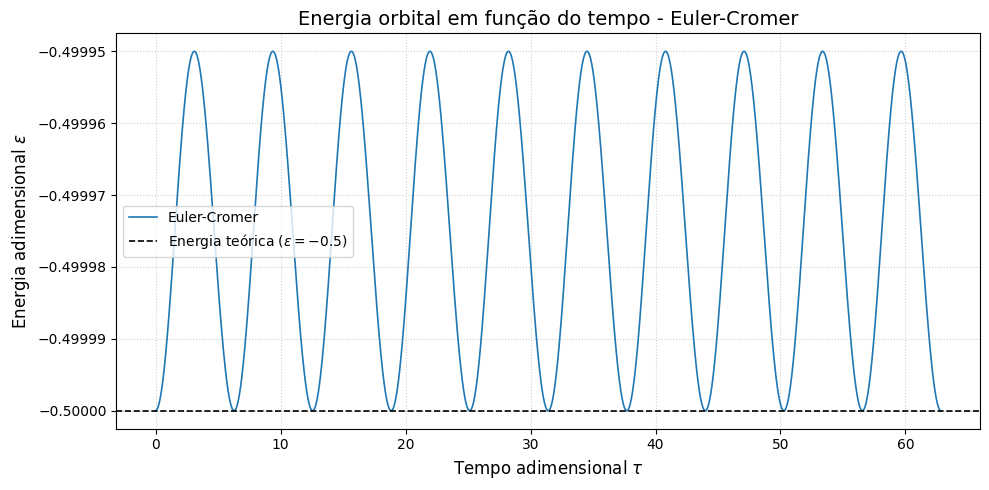

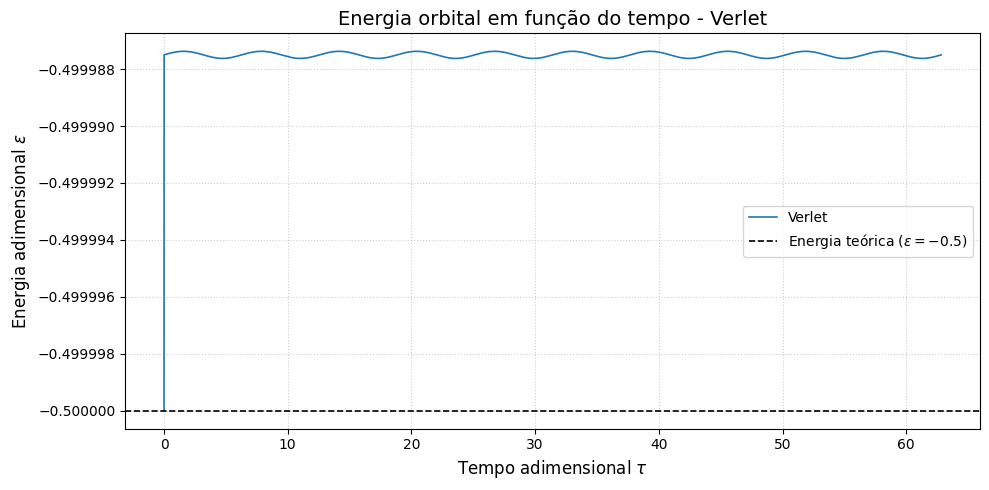

In [ ]:

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Leitura dos arquivos
# ============================================================

tau_ec, energia_ec = np.loadtxt(
    'tarefa1d-saida-1.dat', unpack=True
)

tau_verlet, energia_verlet = np.loadtxt(
    'tarefa1d-saida-2.dat', unpack=True
)


# ============================================================
# Energia teorica
# ============================================================

a = 1.0
energia_teorica = -1.0 / (2.0 * a)


# ============================================================
# Grafico 1: Energia em funcao do tempo - Euler-Cromer
# ============================================================

fig1, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(
    tau_ec,
    energia_ec,
    label='Euler-Cromer',
    linewidth=1.2
)

ax1.axhline(
    energia_teorica,
    color='black',
    linestyle='--',
    linewidth=1.2,
    label=rf'Energia teórica ($\epsilon={energia_teorica}$)'
)

ax1.set_xlabel(r'Tempo adimensional $\tau$', fontsize=12)
ax1.set_ylabel(r'Energia adimensional $\epsilon$', fontsize=12)

ax1.set_title(
    r'Energia orbital em função do tempo - Euler-Cromer',
    fontsize=14
)

ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=10)

ax1.ticklabel_format(axis='y', style='plain', useOffset=False)

fig1.tight_layout()
fig1.savefig('tarefa1d-grafico-euler-cromer.png', dpi=300)


# ============================================================
# Grafico 2: Energia em funcao do tempo - Verlet
# ============================================================

fig2, ax2 = plt.subplots(figsize=(10, 5))

ax2.plot(
    tau_verlet,
    energia_verlet,
    label='Verlet',
    linewidth=1.2
)

ax2.axhline(
    energia_teorica,
    color='black',
    linestyle='--',
    linewidth=1.2,
    label=rf'Energia teórica ($\epsilon={energia_teorica}$)'
)

ax2.set_xlabel(r'Tempo adimensional $\tau$', fontsize=12)
ax2.set_ylabel(r'Energia adimensional $\epsilon$', fontsize=12)

ax2.set_title(
    r'Energia orbital em função do tempo - Verlet',
    fontsize=14
)

ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(fontsize=10)

ax2.ticklabel_format(axis='y', style='plain', useOffset=False)

fig2.tight_layout()
fig2.savefig('tarefa1d-grafico-verlet.png', dpi=300)


plt.show()


### Tarefa 2


Órbita 1 - v_y(0) = 1.1
Inclinação: 0.55000000
Intercepto:  0.00000000
R²:          1.0000000000

Órbita 2 - v_y(0) = 1.2
Inclinação: 0.60000000
Intercepto:  -0.00000000
R²:          1.0000000000

Órbita 3 - v_y(0) = 1.3
Inclinação: 0.65000000
Intercepto:  -0.00000000
R²:          1.0000000000


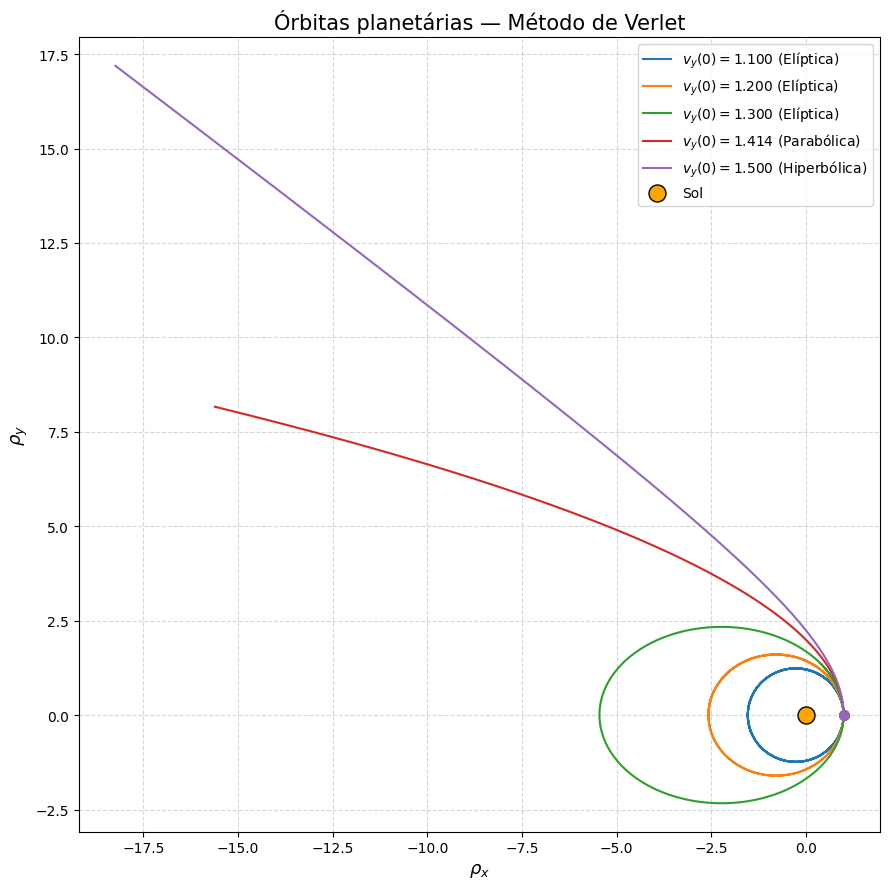

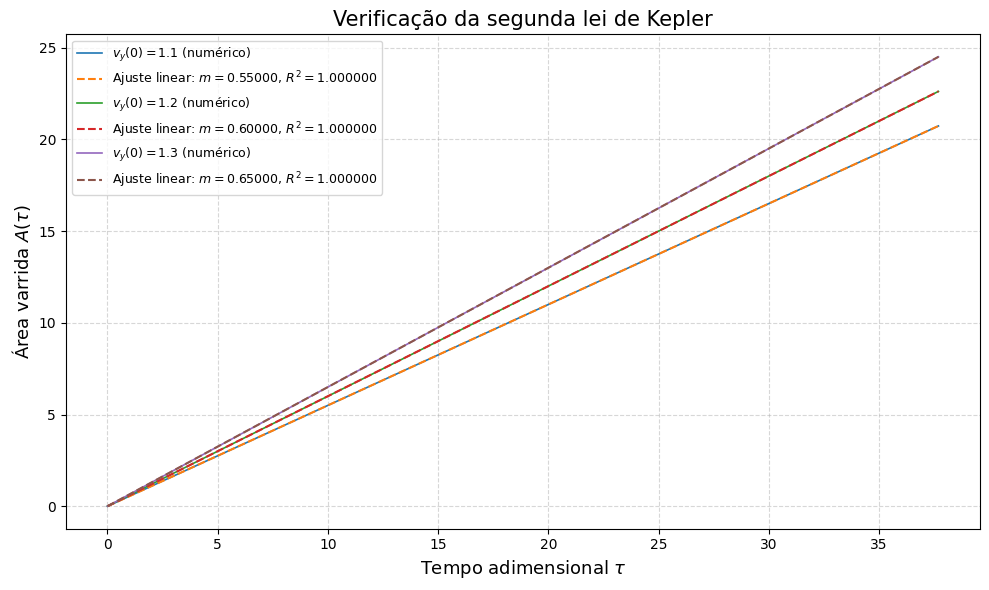

In [ ]:

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Leitura dos cinco arquivos
# ============================================================

arquivos = [
    'tarefa2a-saida-1.dat',
    'tarefa2a-saida-2.dat',
    'tarefa2a-saida-3.dat',
    'tarefa2a-saida-4.dat',
    'tarefa2a-saida-5.dat'
]

velocidades = [1.1, 1.2, 1.3, np.sqrt(2), 1.5]

tipos = [
    'Elíptica',
    'Elíptica',
    'Elíptica',
    'Parabólica',
    'Hiperbólica'
]

dados = [np.loadtxt(arquivo) for arquivo in arquivos]


# ============================================================
# Grafico 1: Trajetorias orbitais
# ============================================================

fig1, ax1 = plt.subplots(figsize=(9, 9))

for i, dado in enumerate(dados):

    rx = dado[:, 1]
    ry = dado[:, 2]

    ax1.plot(
        rx, ry,
        linewidth=1.5,
        label=rf'$v_y(0)={velocidades[i]:.3f}$ ({tipos[i]})'
    )

    # Posição inicial
    ax1.scatter(
        rx[0], ry[0],
        s=45,
        zorder=5
    )

# Representação do Sol na origem
ax1.scatter(
    0, 0,
    color='orange',
    s=150,
    marker='o',
    edgecolors='black',
    label='Sol',
    zorder=6
)

ax1.set_xlabel(r'$\rho_x$', fontsize=13)
ax1.set_ylabel(r'$\rho_y$', fontsize=13)

ax1.set_title(
    'Órbitas planetárias — Método de Verlet',
    fontsize=15
)

ax1.set_aspect('equal', adjustable='datalim')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10)

fig1.tight_layout()
fig1.savefig('tarefa2a-grafico-orbitas.png', dpi=300)


# ============================================================
# Grafico 2: Area varrida em funcao do tempo
# ============================================================

fig2, ax2 = plt.subplots(figsize=(10, 6))

for i in range(3):

    tau = dados[i][:, 0]
    area = dados[i][:, 5]

    # Ajuste linear: A(tau) = m*tau + b
    coeficientes = np.polyfit(tau, area, 1)

    inclinacao = coeficientes[0]
    intercepto = coeficientes[1]

    area_ajustada = np.polyval(coeficientes, tau)

    # Coeficiente de determinacao R²
    residuos = np.sum((area - area_ajustada)**2)
    total = np.sum((area - np.mean(area))**2)
    r2 = 1.0 - residuos/total if total > 0 else 1.0

    # Dados numericos
    ax2.plot(
        tau,
        area,
        linewidth=1.2,
        label=(
            rf'$v_y(0)={velocidades[i]:.1f}$ '
            rf'(numérico)'
        )
    )

    # Ajuste linear
    ax2.plot(
        tau,
        area_ajustada,
        '--',
        linewidth=1.5,
        label=(
            rf'Ajuste linear: $m={inclinacao:.5f}$, '
            rf'$R^2={r2:.6f}$'
        )
    )

    print(f'\nÓrbita {i+1} - v_y(0) = {velocidades[i]:.1f}')
    print(f'Inclinação: {inclinacao:.8f}')
    print(f'Intercepto:  {intercepto:.8f}')
    print(f'R²:          {r2:.10f}')

ax2.set_xlabel(r'Tempo adimensional $\tau$', fontsize=13)
ax2.set_ylabel(r'Área varrida $A(\tau)$', fontsize=13)

ax2.set_title(
    'Verificação da segunda lei de Kepler',
    fontsize=15
)

ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=9)

fig2.tight_layout()
fig2.savefig('tarefa2a-grafico-area.png', dpi=300)


plt.show()


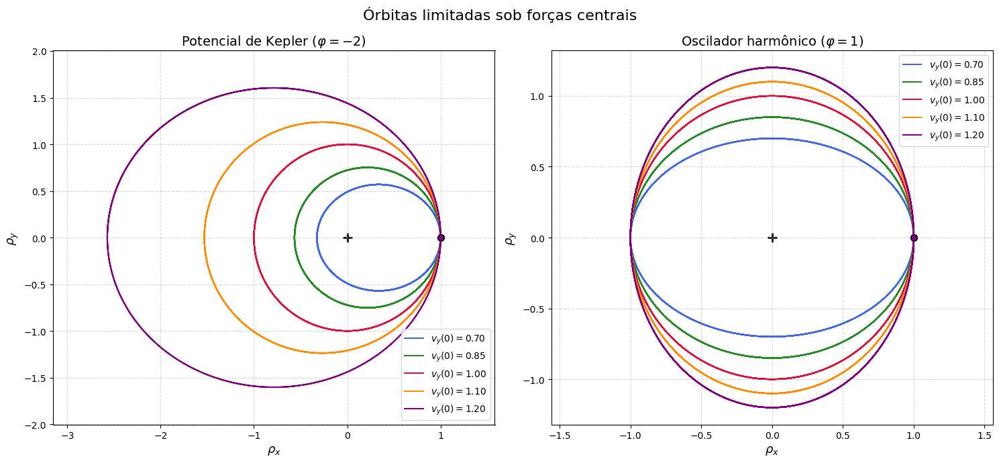

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas_4b():
    velocidades = [0.70, 0.85, 1.00, 1.10, 1.20]

    cores = ['royalblue', 'forestgreen', 'crimson',
             'darkorange', 'purple']

    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    # Potencial de Kepler
    for i, (vy, cor) in enumerate(zip(velocidades, cores), start=1):
        arquivo = f'tarefa-2b-saida-{i}.dat'
        dados = np.loadtxt(arquivo)

        rx, ry = dados[:, 1], dados[:, 2]

        axes[0].plot(rx, ry, color=cor, linewidth=1.5,
                     label=fr'$v_y(0)={vy:.2f}$')

        axes[0].scatter(rx[0], ry[0], color=cor,
                        edgecolors='black', s=45, zorder=5)

    # Oscilador harmônico
    for i, (vy, cor) in enumerate(zip(velocidades, cores), start=6):
        arquivo = f'tarefa-2b-saida-{i}.dat'
        dados = np.loadtxt(arquivo)

        rx, ry = dados[:, 1], dados[:, 2]

        axes[1].plot(rx, ry, color=cor, linewidth=1.5,
                     label=fr'$v_y(0)={vy:.2f}$')

        axes[1].scatter(rx[0], ry[0], color=cor,
                        edgecolors='black', s=45, zorder=5)

    # Configurações dos gráficos
    titulos = [
        r'Potencial de Kepler ($\varphi=-2$)',
        r'Oscilador harmônico ($\varphi=1$)'
    ]

    for ax, titulo in zip(axes, titulos):
        ax.set_title(titulo, fontsize=14)
        ax.set_xlabel(r'$\rho_x$', fontsize=13)
        ax.set_ylabel(r'$\rho_y$', fontsize=13)
        ax.set_aspect('equal', adjustable='datalim')
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(fontsize=10)

        ax.scatter(0, 0, color='black', marker='+',
                   s=100, linewidth=2, label='Centro de força')

    plt.suptitle('Órbitas limitadas sob forças centrais',
                 fontsize=16)

    plt.tight_layout()
    plt.show()


plot_orbitas_4b()

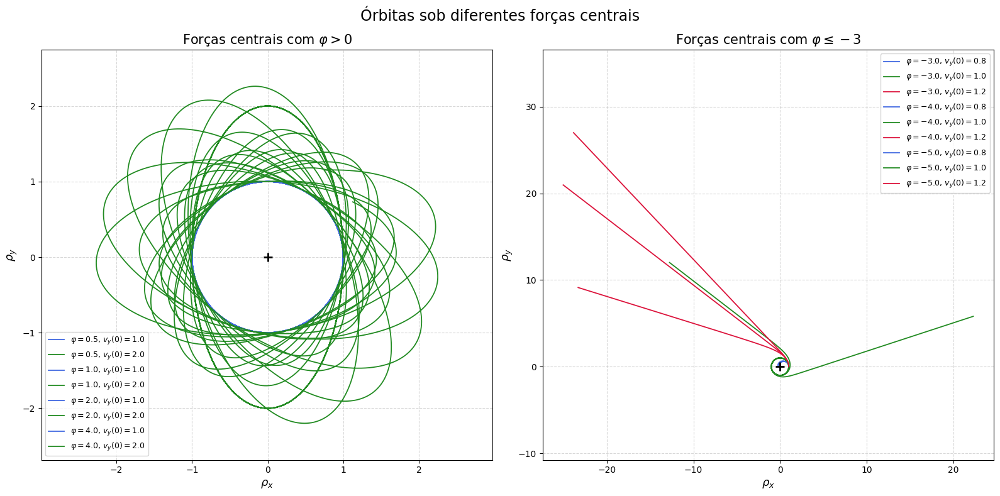

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas_4b():

    # Parâmetros das simulações
    expoentes_positivos = [0.5, 1.0, 2.0, 4.0]
    expoentes_negativos = [-3.0, -4.0, -5.0]

    velocidades_positivas = [1.0, 2.0]
    velocidades_negativas = [0.8, 1.0, 1.2]

    cores = ['royalblue', 'forestgreen', 'crimson']

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # --------------------------------------------------
    # Caso phi > 0
    # --------------------------------------------------

    for i, phi in enumerate(expoentes_positivos, start=1):

        for j, vy in enumerate(velocidades_positivas, start=1):

            arquivo = f'tarefa-2c-saida-{i}-{j}.dat'
            dados = np.loadtxt(arquivo, usecols=(0, 1, 2))

            rx, ry = dados[:, 1], dados[:, 2]

            axes[0].plot(
                rx, ry,
                color=cores[j-1],
                linewidth=1.3,
                label=fr'$\varphi={phi}$, $v_y(0)={vy}$'
            )

    # --------------------------------------------------
    # Caso phi <= -3
    # --------------------------------------------------

    for i, phi in enumerate(expoentes_negativos, start=5):

        for j, vy in enumerate(velocidades_negativas, start=1):

            arquivo = f'tarefa-2c-saida-{i}-{j}.dat'
            dados = np.loadtxt(arquivo, usecols=(0, 1, 2))

            rx, ry = dados[:, 1], dados[:, 2]

            axes[1].plot(
                rx, ry,
                color=cores[j-1],
                linewidth=1.3,
                label=fr'$\varphi={phi}$, $v_y(0)={vy}$'
            )

    # --------------------------------------------------
    # Configurações dos gráficos
    # --------------------------------------------------

    titulos = [
        r'Forças centrais com $\varphi>0$',
        r'Forças centrais com $\varphi\leq-3$'
    ]

    for ax, titulo in zip(axes, titulos):

        ax.set_title(titulo, fontsize=15)
        ax.set_xlabel(r'$\rho_x$', fontsize=13)
        ax.set_ylabel(r'$\rho_y$', fontsize=13)

        ax.set_aspect('equal', adjustable='datalim')
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(fontsize=9)

        ax.scatter(
            0, 0,
            color='black',
            marker='+',
            s=100,
            linewidth=2,
            label='Centro de força',
            zorder=5
        )

    plt.suptitle(
        'Órbitas sob diferentes forças centrais',
        fontsize=17
    )

    plt.tight_layout()
    plt.show()


plot_orbitas_4b()

### Tarefa 3

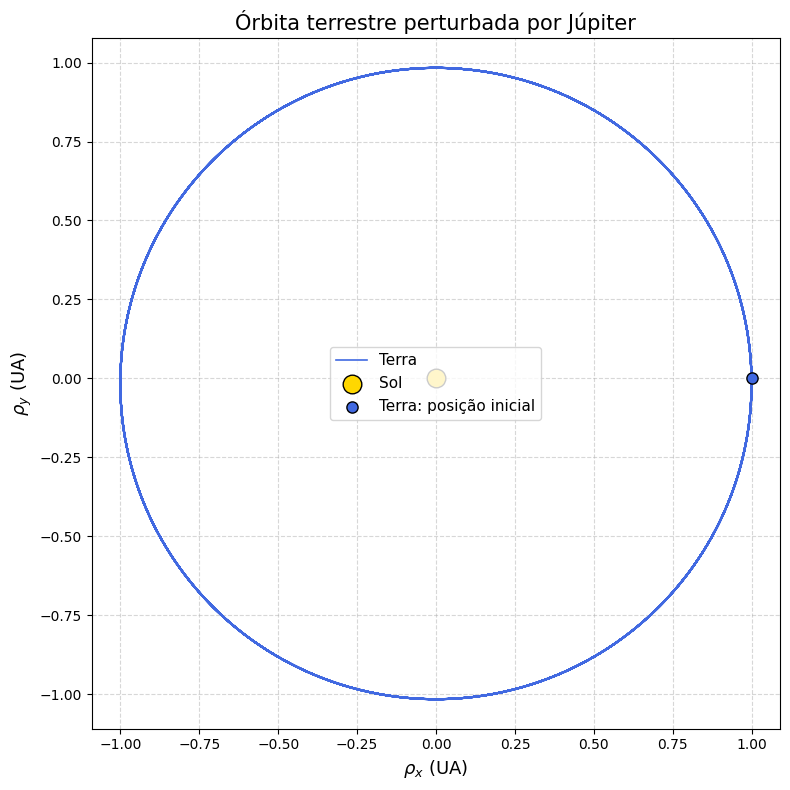

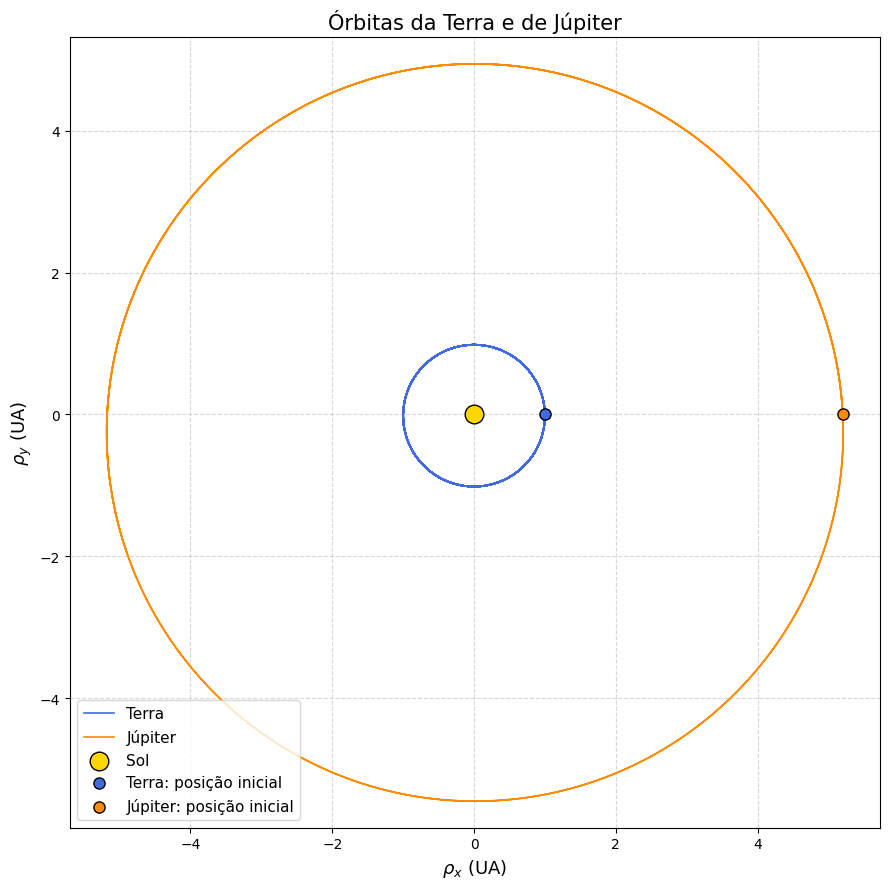

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    tau, rx_terra, ry_terra, rx_jupiter, ry_jupiter = np.loadtxt(
        arquivo, unpack=True
    )

    # Figura 1: Terra e Sol
    fig, ax = plt.subplots(figsize=(8, 8))

    ax.plot(rx_terra, ry_terra, color='royalblue',
            linewidth=1.2, label='Terra')

    ax.scatter(0, 0, color='gold', s=180,
               marker='o', edgecolors='black',
               label='Sol', zorder=5)

    ax.scatter(rx_terra[0], ry_terra[0], color='royalblue',
               edgecolors='black', s=65,
               label='Terra: posição inicial', zorder=6)

    ax.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax.set_title('Órbita terrestre perturbada por Júpiter', fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

    # Figura 2: Terra, Sol e Júpiter
    fig, ax = plt.subplots(figsize=(9, 9))

    ax.plot(rx_terra, ry_terra, color='royalblue',
            linewidth=1.2, label='Terra')

    ax.plot(rx_jupiter, ry_jupiter, color='darkorange',
            linewidth=1.2, label='Júpiter')

    ax.scatter(0, 0, color='gold', s=180,
               marker='o', edgecolors='black',
               label='Sol', zorder=5)

    ax.scatter(rx_terra[0], ry_terra[0], color='royalblue',
               edgecolors='black', s=65,
               label='Terra: posição inicial', zorder=6)

    ax.scatter(rx_jupiter[0], ry_jupiter[0], color='darkorange',
               edgecolors='black', s=65,
               label='Júpiter: posição inicial', zorder=6)

    ax.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax.set_title('Órbitas da Terra e de Júpiter', fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()


# Simulação de três corpos — Método de Verlet
plot_orbitas('tarefa3b-saida-1.dat')


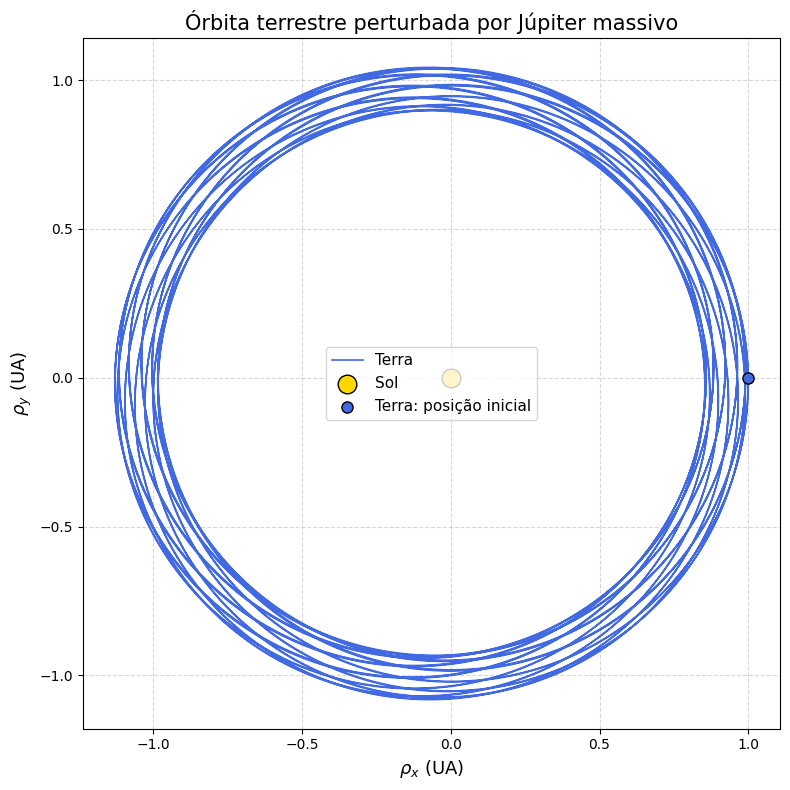

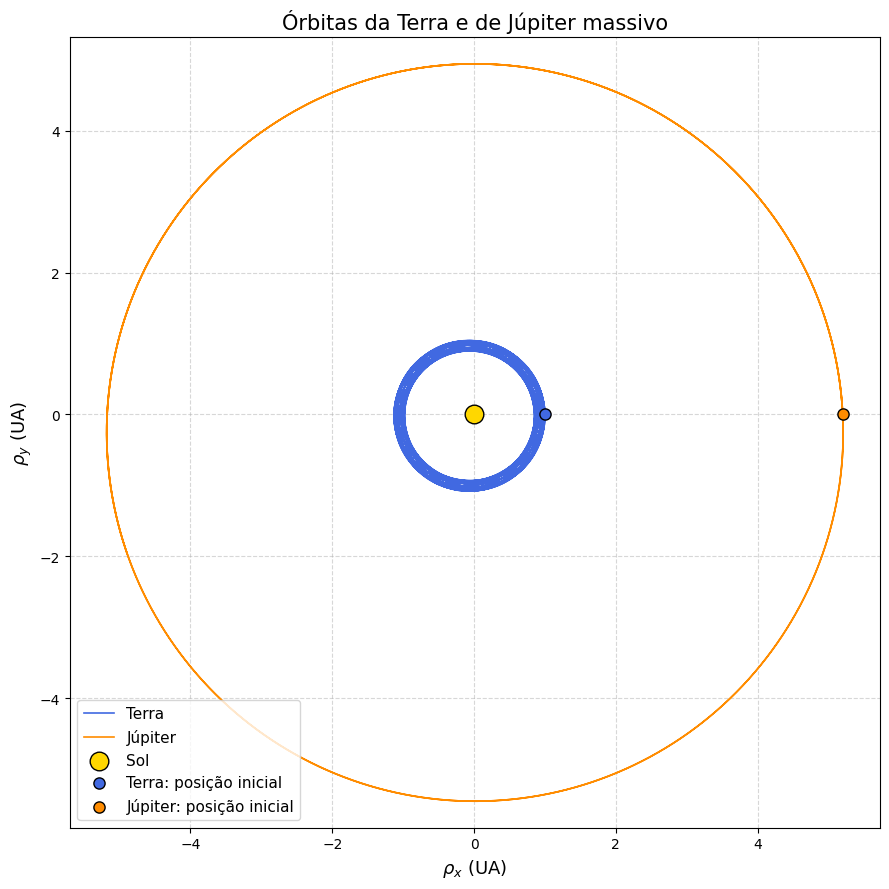

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    tau, rx_terra, ry_terra, rx_jupiter, ry_jupiter = np.loadtxt(
        arquivo, unpack=True
    )

    # Figura 1: Terra e Sol
    fig, ax = plt.subplots(figsize=(8, 8))

    ax.plot(rx_terra, ry_terra, color='royalblue',
            linewidth=1.2, label='Terra')

    ax.scatter(0, 0, color='gold', s=180,
               marker='o', edgecolors='black',
               label='Sol', zorder=5)

    ax.scatter(rx_terra[0], ry_terra[0], color='royalblue',
               edgecolors='black', s=65,
               label='Terra: posição inicial', zorder=6)

    ax.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax.set_title('Órbita terrestre perturbada por Júpiter massivo', fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

    # Figura 2: Terra, Sol e Júpiter
    fig, ax = plt.subplots(figsize=(9, 9))

    ax.plot(rx_terra, ry_terra, color='royalblue',
            linewidth=1.2, label='Terra')

    ax.plot(rx_jupiter, ry_jupiter, color='darkorange',
            linewidth=1.2, label='Júpiter')

    ax.scatter(0, 0, color='gold', s=180,
               marker='o', edgecolors='black',
               label='Sol', zorder=5)

    ax.scatter(rx_terra[0], ry_terra[0], color='royalblue',
               edgecolors='black', s=65,
               label='Terra: posição inicial', zorder=6)

    ax.scatter(rx_jupiter[0], ry_jupiter[0], color='darkorange',
               edgecolors='black', s=65,
               label='Júpiter: posição inicial', zorder=6)

    ax.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax.set_title('Órbitas da Terra e de Júpiter massivo', fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()


# Simulação de três corpos — Método de Verlet
plot_orbitas('tarefa3c-saida-1.dat')


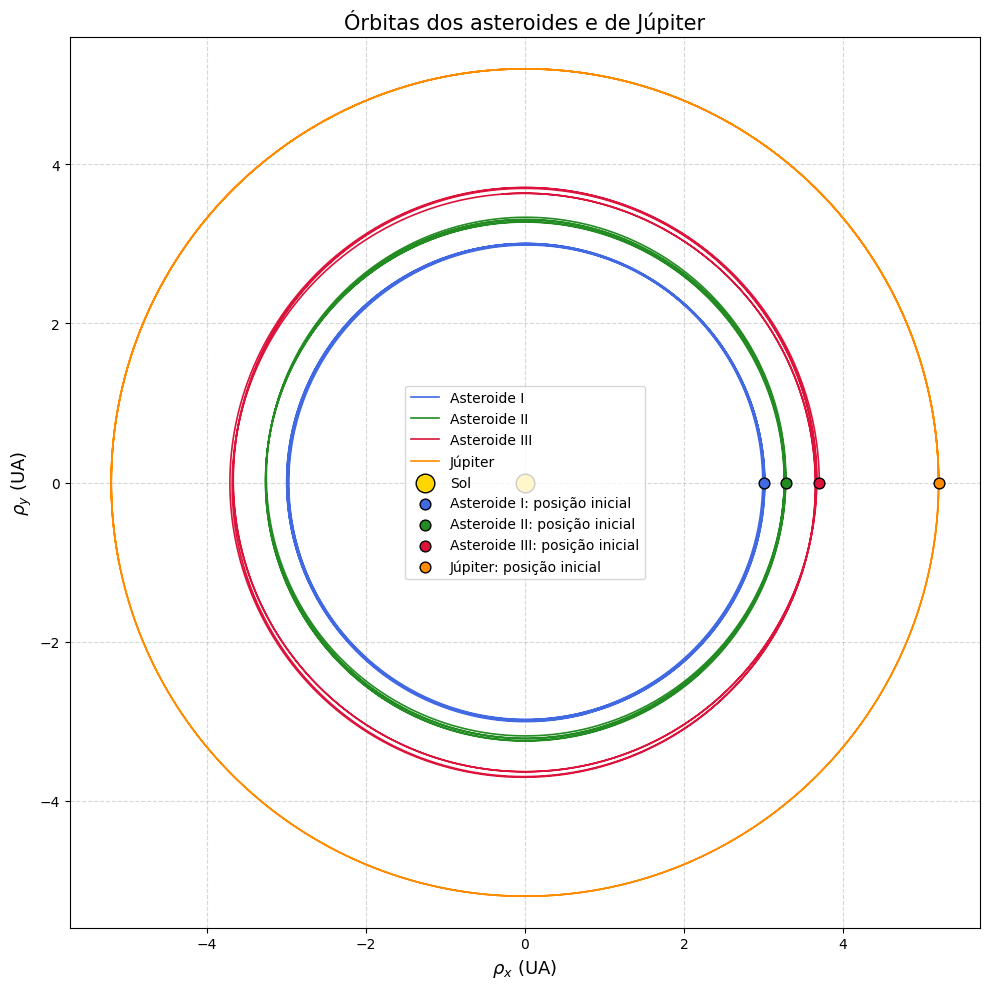

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]

    rx_i, ry_i = dados[:, 1], dados[:, 2]
    rx_ii, ry_ii = dados[:, 3], dados[:, 4]
    rx_iii, ry_iii = dados[:, 5], dados[:, 6]
    rx_jupiter, ry_jupiter = dados[:, 7], dados[:, 8]

    # Construção do gráfico
    fig, ax = plt.subplots(figsize=(10, 10))

    # Trajetórias dos asteroides e de Júpiter
    ax.plot(rx_i, ry_i, color='royalblue',
            linewidth=1.2, label='Asteroide I')

    ax.plot(rx_ii, ry_ii, color='forestgreen',
            linewidth=1.2, label='Asteroide II')

    ax.plot(rx_iii, ry_iii, color='crimson',
            linewidth=1.2, label='Asteroide III')

    ax.plot(rx_jupiter, ry_jupiter, color='darkorange',
            linewidth=1.2, label='Júpiter')

    # Representação do Sol na origem
    ax.scatter(0, 0, color='gold', s=180,
               marker='o', edgecolors='black',
               label='Sol', zorder=5)

    # Posições iniciais
    ax.scatter(rx_i[0], ry_i[0], color='royalblue',
               edgecolors='black', s=60,
               label='Asteroide I: posição inicial', zorder=6)

    ax.scatter(rx_ii[0], ry_ii[0], color='forestgreen',
               edgecolors='black', s=60,
               label='Asteroide II: posição inicial', zorder=6)

    ax.scatter(rx_iii[0], ry_iii[0], color='crimson',
               edgecolors='black', s=60,
               label='Asteroide III: posição inicial', zorder=6)

    ax.scatter(rx_jupiter[0], ry_jupiter[0], color='darkorange',
               edgecolors='black', s=60,
               label='Júpiter: posição inicial', zorder=6)

    # Configurações do gráfico
    ax.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax.set_title('Órbitas dos asteroides e de Júpiter',
                 fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=10)

    plt.tight_layout()
    plt.show()


# Simulação — Método de Verlet
plot_orbitas('tarefa3d-saida-1.dat')


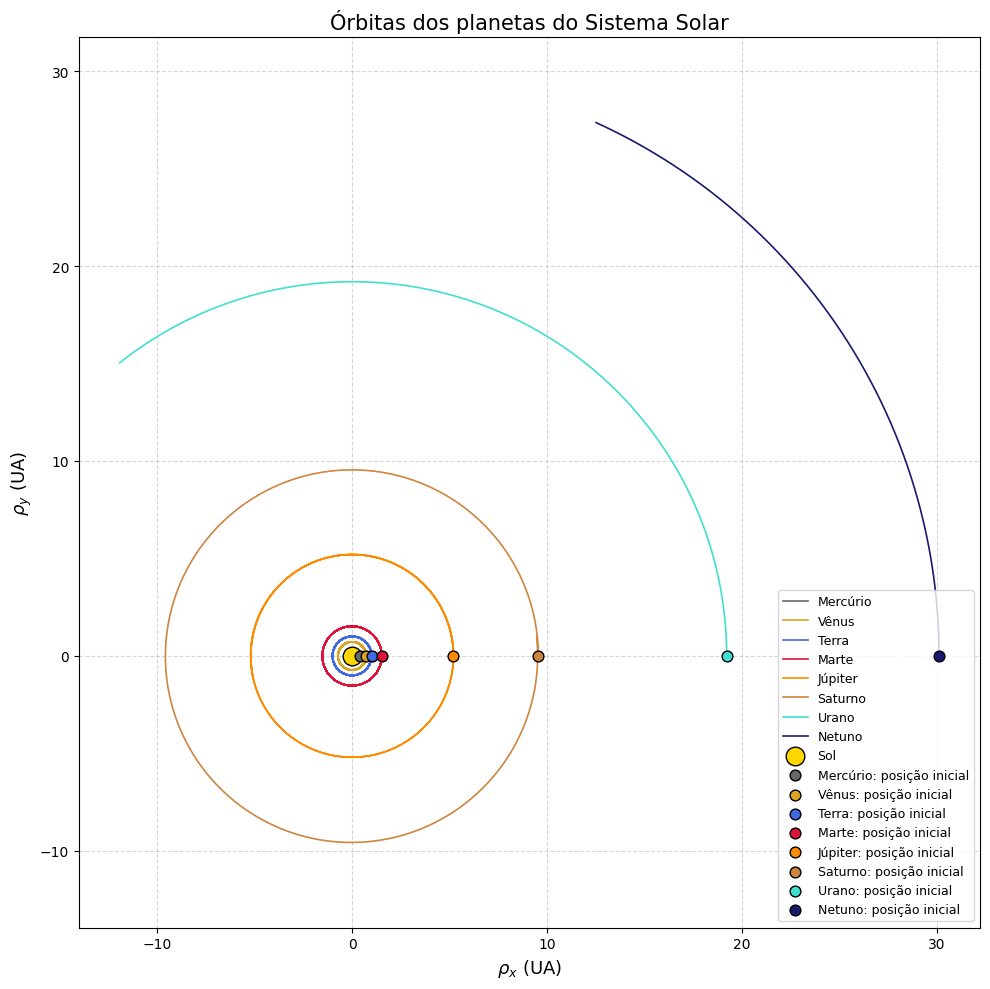

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]

    rx_mercurio, ry_mercurio = dados[:, 1], dados[:, 2]
    rx_venus, ry_venus = dados[:, 3], dados[:, 4]
    rx_terra, ry_terra = dados[:, 5], dados[:, 6]
    rx_marte, ry_marte = dados[:, 7], dados[:, 8]
    rx_jupiter, ry_jupiter = dados[:, 9], dados[:, 10]
    rx_saturno, ry_saturno = dados[:, 11], dados[:, 12]
    rx_urano, ry_urano = dados[:, 13], dados[:, 14]
    rx_netuno, ry_netuno = dados[:, 15], dados[:, 16]

    # Construção do gráfico
    fig, ax = plt.subplots(figsize=(10, 10))

    # Trajetórias dos planetas
    ax.plot(rx_mercurio, ry_mercurio, color='dimgray',
            linewidth=1.2, label='Mercúrio')

    ax.plot(rx_venus, ry_venus, color='goldenrod',
            linewidth=1.2, label='Vênus')

    ax.plot(rx_terra, ry_terra, color='royalblue',
            linewidth=1.2, label='Terra')

    ax.plot(rx_marte, ry_marte, color='crimson',
            linewidth=1.2, label='Marte')

    ax.plot(rx_jupiter, ry_jupiter, color='darkorange',
            linewidth=1.2, label='Júpiter')

    ax.plot(rx_saturno, ry_saturno, color='peru',
            linewidth=1.2, label='Saturno')

    ax.plot(rx_urano, ry_urano, color='turquoise',
            linewidth=1.2, label='Urano')

    ax.plot(rx_netuno, ry_netuno, color='midnightblue',
            linewidth=1.2, label='Netuno')

    # Representação do Sol na origem
    ax.scatter(0, 0, color='gold', s=180,
               marker='o', edgecolors='black',
               label='Sol', zorder=5)

    # Posições iniciais
    ax.scatter(rx_mercurio[0], ry_mercurio[0], color='dimgray',
               edgecolors='black', s=60,
               label='Mercúrio: posição inicial', zorder=6)

    ax.scatter(rx_venus[0], ry_venus[0], color='goldenrod',
               edgecolors='black', s=60,
               label='Vênus: posição inicial', zorder=6)

    ax.scatter(rx_terra[0], ry_terra[0], color='royalblue',
               edgecolors='black', s=60,
               label='Terra: posição inicial', zorder=6)

    ax.scatter(rx_marte[0], ry_marte[0], color='crimson',
               edgecolors='black', s=60,
               label='Marte: posição inicial', zorder=6)

    ax.scatter(rx_jupiter[0], ry_jupiter[0], color='darkorange',
               edgecolors='black', s=60,
               label='Júpiter: posição inicial', zorder=6)

    ax.scatter(rx_saturno[0], ry_saturno[0], color='peru',
               edgecolors='black', s=60,
               label='Saturno: posição inicial', zorder=6)

    ax.scatter(rx_urano[0], ry_urano[0], color='turquoise',
               edgecolors='black', s=60,
               label='Urano: posição inicial', zorder=6)

    ax.scatter(rx_netuno[0], ry_netuno[0], color='midnightblue',
               edgecolors='black', s=60,
               label='Netuno: posição inicial', zorder=6)

    # Configurações do gráfico
    ax.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax.set_title('Órbitas dos planetas do Sistema Solar',
                 fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()


# Simulação — Método de Verlet
plot_orbitas('tarefa3e-saida-1.dat')

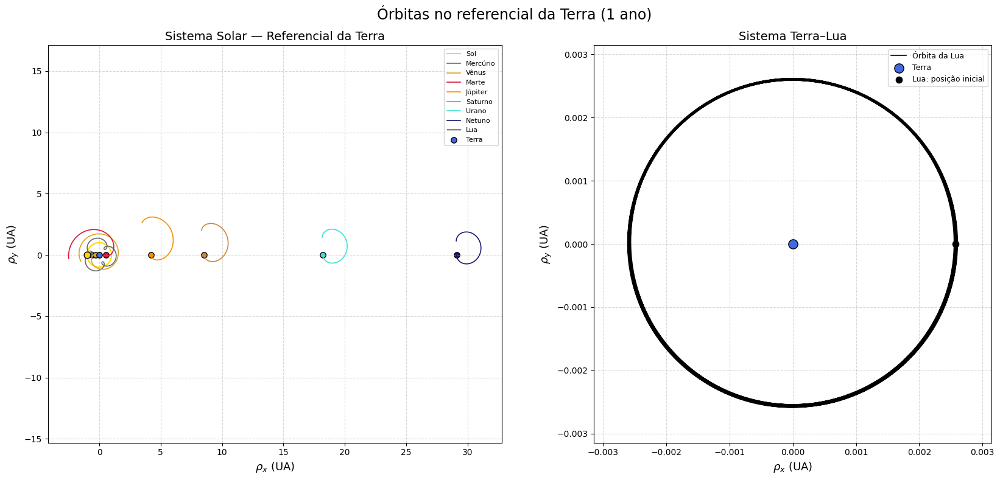

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]

    rx_mercurio, ry_mercurio = dados[:, 1], dados[:, 2]
    rx_venus, ry_venus = dados[:, 3], dados[:, 4]
    rx_terra, ry_terra = dados[:, 5], dados[:, 6]
    rx_marte, ry_marte = dados[:, 7], dados[:, 8]
    rx_jupiter, ry_jupiter = dados[:, 9], dados[:, 10]
    rx_saturno, ry_saturno = dados[:, 11], dados[:, 12]
    rx_urano, ry_urano = dados[:, 13], dados[:, 14]
    rx_netuno, ry_netuno = dados[:, 15], dados[:, 16]
    rx_lua, ry_lua = dados[:, 17], dados[:, 18]

    # Posição do Sol no referencial da Terra
    rx_sol = -dados[:, 19]
    ry_sol = -dados[:, 20]

    # Construção dos gráficos
    fig, (ax, ax_lua) = plt.subplots(1, 2, figsize=(17, 8))

    # --------------------------------------------------
    # Gráfico 1: Sistema Solar no referencial da Terra
    # --------------------------------------------------

    # Trajetórias dos planetas
    ax.plot(rx_sol, ry_sol, color='gold',
            linewidth=1.5, label='Sol')

    ax.plot(rx_mercurio, ry_mercurio, color='dimgray',
            linewidth=1.2, label='Mercúrio')

    ax.plot(rx_venus, ry_venus, color='goldenrod',
            linewidth=1.2, label='Vênus')

    ax.plot(rx_marte, ry_marte, color='crimson',
            linewidth=1.2, label='Marte')

    ax.plot(rx_jupiter, ry_jupiter, color='darkorange',
            linewidth=1.2, label='Júpiter')

    ax.plot(rx_saturno, ry_saturno, color='peru',
            linewidth=1.2, label='Saturno')

    ax.plot(rx_urano, ry_urano, color='turquoise',
            linewidth=1.2, label='Urano')

    ax.plot(rx_netuno, ry_netuno, color='midnightblue',
            linewidth=1.2, label='Netuno')

    ax.plot(rx_lua, ry_lua, color='black',
            linewidth=1.0, label='Lua')

    # Terra na origem
    ax.scatter(0, 0, color='royalblue', s=45,
               marker='o', edgecolors='black',
               label='Terra', zorder=6)

    # Posições iniciais
    ax.scatter(rx_sol[0], ry_sol[0], color='gold',
               edgecolors='black', s=60, zorder=5)

    ax.scatter(rx_mercurio[0], ry_mercurio[0],
               color='dimgray', edgecolors='black', s=45)

    ax.scatter(rx_venus[0], ry_venus[0],
               color='goldenrod', edgecolors='black', s=45)

    ax.scatter(rx_marte[0], ry_marte[0],
               color='crimson', edgecolors='black', s=45)

    ax.scatter(rx_jupiter[0], ry_jupiter[0],
               color='darkorange', edgecolors='black', s=45)

    ax.scatter(rx_saturno[0], ry_saturno[0],
               color='peru', edgecolors='black', s=45)

    ax.scatter(rx_urano[0], ry_urano[0],
               color='turquoise', edgecolors='black', s=45)

    ax.scatter(rx_netuno[0], ry_netuno[0],
               color='midnightblue', edgecolors='black', s=45)

    ax.scatter(rx_lua[0], ry_lua[0],
               color='black', edgecolors='black', s=35)

    # Configurações do gráfico
    ax.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax.set_title('Sistema Solar — Referencial da Terra', fontsize=14)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=8)

    # --------------------------------------------------
    # Gráfico 2: Ampliação da órbita da Lua
    # --------------------------------------------------

    ax_lua.plot(rx_lua, ry_lua, color='black',
                linewidth=1.2, label='Órbita da Lua')

    ax_lua.scatter(0, 0, color='royalblue', s=120,
                   edgecolors='black', label='Terra', zorder=5)

    ax_lua.scatter(rx_lua[0], ry_lua[0], color='black',
                   edgecolors='black', s=55,
                   label='Lua: posição inicial', zorder=6)

    # Limites da ampliação
    raio_lua = np.max(np.sqrt(rx_lua**2 + ry_lua**2))
    limite = 1.2 * raio_lua

    ax_lua.set_xlim(-limite, limite)
    ax_lua.set_ylim(-limite, limite)

    ax_lua.set_xlabel(r'$\rho_x$ (UA)', fontsize=13)
    ax_lua.set_ylabel(r'$\rho_y$ (UA)', fontsize=13)
    ax_lua.set_title('Sistema Terra–Lua', fontsize=14)

    ax_lua.set_aspect('equal')
    ax_lua.grid(True, linestyle='--', alpha=0.5)
    ax_lua.legend(fontsize=9)

    plt.suptitle('Órbitas no referencial da Terra (1 ano)', fontsize=17)
    plt.tight_layout()
    plt.show()


# Simulação — Método de Verlet
plot_orbitas('tarefa-3f-saida-1.dat')

### Tarefa 4

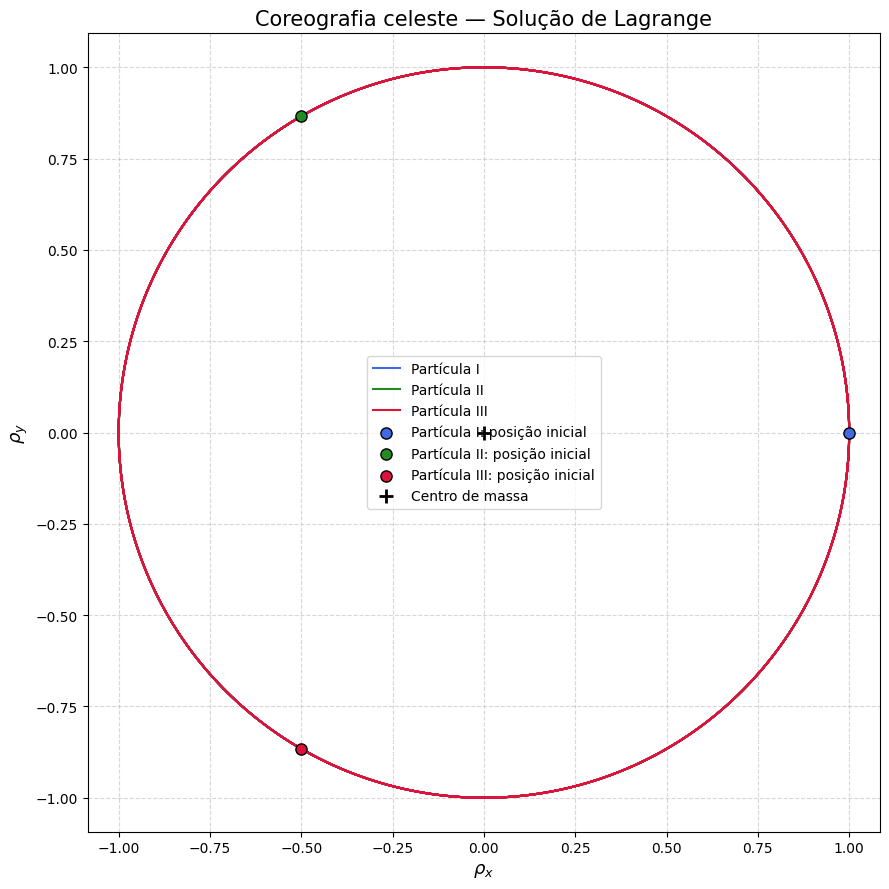

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]

    rx_i, ry_i = dados[:, 1], dados[:, 2]
    rx_ii, ry_ii = dados[:, 3], dados[:, 4]
    rx_iii, ry_iii = dados[:, 5], dados[:, 6]

    # Construção do gráfico
    fig, ax = plt.subplots(figsize=(9, 9))

    # Trajetórias das partículas
    ax.plot(rx_i, ry_i, color='royalblue',
            linewidth=1.5, label='Partícula I')

    ax.plot(rx_ii, ry_ii, color='forestgreen',
            linewidth=1.5, label='Partícula II')

    ax.plot(rx_iii, ry_iii, color='crimson',
            linewidth=1.5, label='Partícula III')

    # Posições iniciais
    ax.scatter(rx_i[0], ry_i[0], color='royalblue',
               edgecolors='black', s=65,
               label='Partícula I: posição inicial', zorder=5)

    ax.scatter(rx_ii[0], ry_ii[0], color='forestgreen',
               edgecolors='black', s=65,
               label='Partícula II: posição inicial', zorder=5)

    ax.scatter(rx_iii[0], ry_iii[0], color='crimson',
               edgecolors='black', s=65,
               label='Partícula III: posição inicial', zorder=5)

    # Centro de massa
    ax.scatter(0, 0, color='black', marker='+',
               s=100, linewidth=2,
               label='Centro de massa', zorder=6)

    # Configurações do gráfico
    ax.set_xlabel(r'$\rho_x$', fontsize=13)
    ax.set_ylabel(r'$\rho_y$', fontsize=13)
    ax.set_title('Coreografia celeste — Solução de Lagrange',
                 fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=10)

    plt.tight_layout()
    plt.show()


# Simulação — Método de Runge-Kutta de quarta ordem
plot_orbitas('tarefa4a-saida-1.dat')

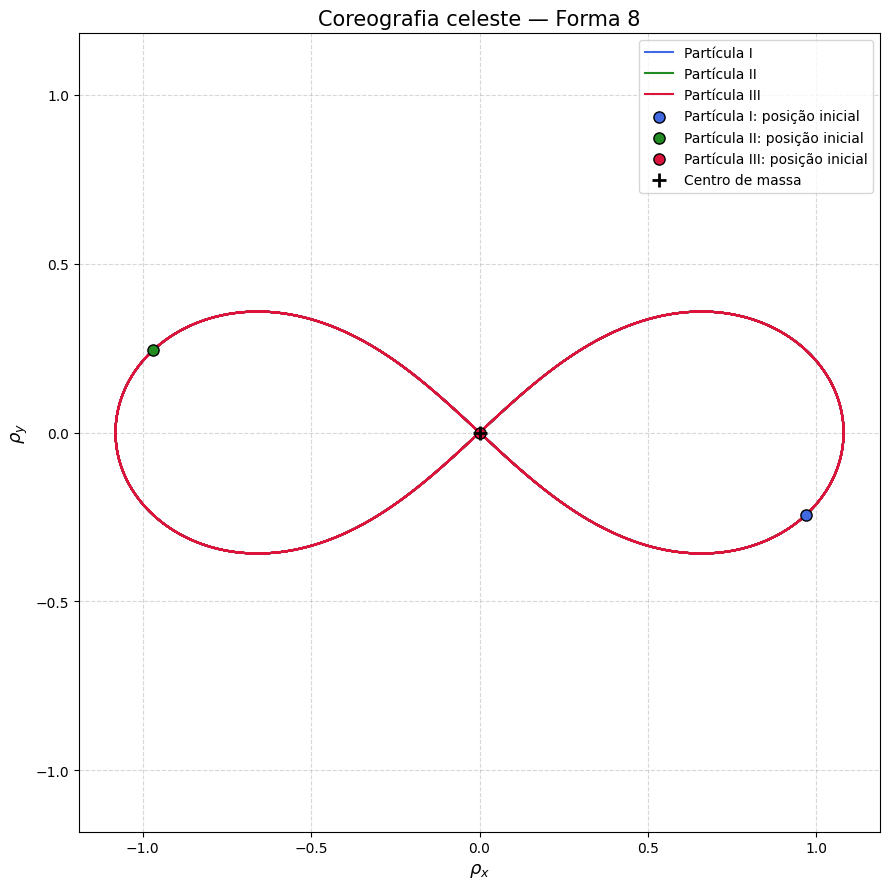

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]

    rx_i, ry_i = dados[:, 1], dados[:, 2]
    rx_ii, ry_ii = dados[:, 3], dados[:, 4]
    rx_iii, ry_iii = dados[:, 5], dados[:, 6]

    # Construção do gráfico
    fig, ax = plt.subplots(figsize=(9, 9))

    # Trajetórias das partículas
    ax.plot(rx_i, ry_i, color='royalblue',
            linewidth=1.5, label='Partícula I')

    ax.plot(rx_ii, ry_ii, color='forestgreen',
            linewidth=1.5, label='Partícula II')

    ax.plot(rx_iii, ry_iii, color='crimson',
            linewidth=1.5, label='Partícula III')

    # Posições iniciais
    ax.scatter(rx_i[0], ry_i[0], color='royalblue',
               edgecolors='black', s=65,
               label='Partícula I: posição inicial', zorder=5)

    ax.scatter(rx_ii[0], ry_ii[0], color='forestgreen',
               edgecolors='black', s=65,
               label='Partícula II: posição inicial', zorder=5)

    ax.scatter(rx_iii[0], ry_iii[0], color='crimson',
               edgecolors='black', s=65,
               label='Partícula III: posição inicial', zorder=5)

    # Centro de massa
    ax.scatter(0, 0, color='black', marker='+',
               s=100, linewidth=2,
               label='Centro de massa', zorder=6)

    # Configurações do gráfico
    ax.set_xlabel(r'$\rho_x$', fontsize=13)
    ax.set_ylabel(r'$\rho_y$', fontsize=13)
    ax.set_title('Coreografia celeste — Forma 8',
                 fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=10)

    plt.tight_layout()
    plt.show()


# Simulação — Método de Runge-Kutta de quarta ordem
plot_orbitas('tarefa4b-saida-1.dat')

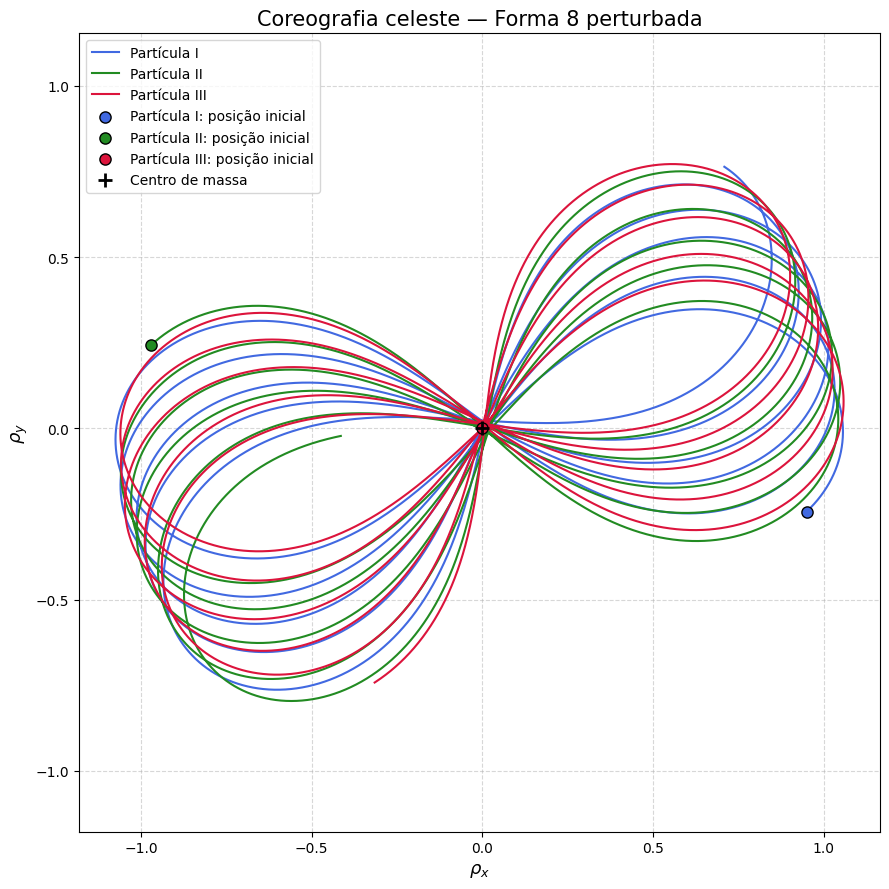

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_orbitas(arquivo):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]

    rx_i, ry_i = dados[:, 1], dados[:, 2]
    rx_ii, ry_ii = dados[:, 3], dados[:, 4]
    rx_iii, ry_iii = dados[:, 5], dados[:, 6]

    # Construção do gráfico
    fig, ax = plt.subplots(figsize=(9, 9))

    # Trajetórias das partículas
    ax.plot(rx_i, ry_i, color='royalblue',
            linewidth=1.5, label='Partícula I')

    ax.plot(rx_ii, ry_ii, color='forestgreen',
            linewidth=1.5, label='Partícula II')

    ax.plot(rx_iii, ry_iii, color='crimson',
            linewidth=1.5, label='Partícula III')

    # Posições iniciais
    ax.scatter(rx_i[0], ry_i[0], color='royalblue',
               edgecolors='black', s=65,
               label='Partícula I: posição inicial', zorder=5)

    ax.scatter(rx_ii[0], ry_ii[0], color='forestgreen',
               edgecolors='black', s=65,
               label='Partícula II: posição inicial', zorder=5)

    ax.scatter(rx_iii[0], ry_iii[0], color='crimson',
               edgecolors='black', s=65,
               label='Partícula III: posição inicial', zorder=5)

    # Centro de massa
    ax.scatter(0, 0, color='black', marker='+',
               s=100, linewidth=2,
               label='Centro de massa', zorder=6)

    # Configurações do gráfico
    ax.set_xlabel(r'$\rho_x$', fontsize=13)
    ax.set_ylabel(r'$\rho_y$', fontsize=13)
    ax.set_title('Coreografia celeste — Forma 8 perturbada',
                 fontsize=15)

    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=10)

    plt.tight_layout()
    plt.show()


# Simulação — Método de Runge-Kutta de quarta ordem
plot_orbitas('tarefa4c-saida-1.dat')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, display
from google.colab import files

def animar_orbitas(arquivo, max_frames=120, fps=10):
    # Leitura dos dados
    dados = np.loadtxt(arquivo)

    tau = dados[:, 0]

    rx_i, ry_i = dados[:, 1], dados[:, 2]
    rx_ii, ry_ii = dados[:, 3], dados[:, 4]
    rx_iii, ry_iii = dados[:, 5], dados[:, 6]

    n = len(tau)

    if n < 2:
        raise ValueError("O arquivo deve conter pelo menos duas linhas.")

    # Seleção dos quadros
    indices = np.unique(
        np.linspace(0, n - 1, min(n, max_frames), dtype=int)
    )

    # Limites fixos dos eixos
    x = np.concatenate((rx_i, rx_ii, rx_iii))
    y = np.concatenate((ry_i, ry_ii, ry_iii))

    xmin, xmax = np.min(x), np.max(x)
    ymin, ymax = np.min(y), np.max(y)

    centro_x = (xmin + xmax) / 2
    centro_y = (ymin + ymax) / 2

    amplitude = 0.55 * max(xmax - xmin, ymax - ymin)
    amplitude = max(amplitude, 0.1)

    # Construção do gráfico
    fig, ax = plt.subplots(figsize=(9, 9))

    ax.set_xlim(centro_x - amplitude, centro_x + amplitude)
    ax.set_ylim(centro_y - amplitude, centro_y + amplitude)

    ax.set_aspect('equal')
    ax.set_xlabel(r'$\rho_x$', fontsize=13)
    ax.set_ylabel(r'$\rho_y$', fontsize=13)
    ax.set_title('Coreografia celeste — Forma 8 perturbada',
                 fontsize=15)

    ax.grid(True, linestyle='--', alpha=0.5)

    # Linhas das trajetórias
    linha_i, = ax.plot([], [], color='royalblue',
                       linewidth=1.5, label='Partícula I')

    linha_ii, = ax.plot([], [], color='forestgreen',
                        linewidth=1.5, label='Partícula II')

    linha_iii, = ax.plot([], [], color='crimson',
                         linewidth=1.5, label='Partícula III')

    # Marcadores das posições instantâneas
    ponto_i, = ax.plot([], [], 'o', color='royalblue',
                       markeredgecolor='black', markersize=8)

    ponto_ii, = ax.plot([], [], 'o', color='forestgreen',
                        markeredgecolor='black', markersize=8)

    ponto_iii, = ax.plot([], [], 'o', color='crimson',
                         markeredgecolor='black', markersize=8)

    # Posições iniciais
    ax.scatter(rx_i[0], ry_i[0], color='royalblue',
               edgecolors='black', s=65,
               label='Partícula I: posição inicial', zorder=5)

    ax.scatter(rx_ii[0], ry_ii[0], color='forestgreen',
               edgecolors='black', s=65,
               label='Partícula II: posição inicial', zorder=5)

    ax.scatter(rx_iii[0], ry_iii[0], color='crimson',
               edgecolors='black', s=65,
               label='Partícula III: posição inicial', zorder=5)

    # Centro de massa
    ax.scatter(0, 0, color='black', marker='+',
               s=100, linewidth=2,
               label='Centro de massa', zorder=6)

    # Indicador de tempo
    texto_tempo = ax.text(
        0.03, 0.97, '',
        transform=ax.transAxes,
        verticalalignment='top',
        fontsize=12,
        bbox=dict(facecolor='white', alpha=0.8)
    )

    ax.legend(fontsize=9, loc='best')
    plt.tight_layout()

    # Inicialização
    def inicializar():
        linha_i.set_data([], [])
        linha_ii.set_data([], [])
        linha_iii.set_data([], [])

        ponto_i.set_data([], [])
        ponto_ii.set_data([], [])
        ponto_iii.set_data([], [])

        texto_tempo.set_text('')

        return (
            linha_i, linha_ii, linha_iii,
            ponto_i, ponto_ii, ponto_iii,
            texto_tempo
        )

    # Atualização dos quadros
    def atualizar(frame):
        k = indices[frame]

        linha_i.set_data(rx_i[:k+1], ry_i[:k+1])
        linha_ii.set_data(rx_ii[:k+1], ry_ii[:k+1])
        linha_iii.set_data(rx_iii[:k+1], ry_iii[:k+1])

        ponto_i.set_data([rx_i[k]], [ry_i[k]])
        ponto_ii.set_data([rx_ii[k]], [ry_ii[k]])
        ponto_iii.set_data([rx_iii[k]], [ry_iii[k]])

        texto_tempo.set_text(rf'$\tau = {tau[k]:.3f}$')

        return (
            linha_i, linha_ii, linha_iii,
            ponto_i, ponto_ii, ponto_iii,
            texto_tempo
        )

    # Geração da animação
    animacao = FuncAnimation(
        fig,
        atualizar,
        frames=len(indices),
        init_func=inicializar,
        interval=1000/fps,
        blit=True,
        repeat=True
    )

    # Exibição no notebook
    display(HTML(animacao.to_jshtml(fps=fps)))

    # Exportação para GIF
    nome_saida = arquivo.replace('.dat', '.gif')

    animacao.save(
        nome_saida,
        writer=PillowWriter(fps=fps),
        dpi=100
    )

    plt.close(fig)

    print(f"Animação salva em: {nome_saida}")

    # Download automático no Google Colab
    files.download(nome_saida)


# Simulação — Método de Runge-Kutta de quarta ordem
animar_orbitas('tarefa-4c-saida-1.dat', max_frames=120, fps=10)

Animação salva em: tarefa-4c-saida-1.gif


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>